# FreshTrack Computer Vision Pipeline for Fruit Inspection

## Project Overview

FreshTrack is a produce supply chain company that receives mixed fruit crates in warehouses. Manual inspection of fruits is slow and inconsistent under changing lighting conditions.

This project develops a Computer Vision pipeline using OpenCV to automate fruit inspection tasks.

The system performs:

- Fruit identification based on color information
- Image enhancement and noise removal
- Shape and edge feature detection
- Fruit counting from mixed fruit images

## Objectives

The main objectives of this project are:

1. Identify fruit types using color segmentation.
2. Improve image quality using filtering techniques.
3. Apply morphological operations for mask cleanup.
4. Detect edges, corners, and circular fruit shapes.
5. Build a complete computer vision pipeline for fruit analysis.

## Tools and Technologies

- Python
- OpenCV
- NumPy
- Matplotlib

## Dataset and Images

The project uses fruit images from the Fruits-360 dataset subset along with provided calibration and morphology images.

Images used:

- red_apple.png
- green_apple.png
- banana.png
- strawberry.png
- orange.png
- lime.png
- mixed_fruit_bowl.jpeg
- morphology.png
- chessboard.png

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Image display ko size set gareko
plt.rcParams["figure.figsize"] = (8, 5)

# Dataset ra output ko path define garne
DATA_PATH = "data/"
OUTPUT_PATH = "outputs/"

# Output folder create garne
os.makedirs(OUTPUT_PATH, exist_ok=True)

print("Environment setup completed")

Environment setup completed


In [2]:
#-> Helper Function banako 

def load_image(filename):
    # Image ko full path banaune
    path = os.path.join(DATA_PATH, filename)
    
    img = cv2.imread(path)
    
    return img


def display_rgb(img, title="Image"):
    # OpenCV BGR format lai RGB ma convert garnalai
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.imshow(rgb)
    plt.title(title)
    plt.axis("off")
    plt.show()


def display_gray(img, title="Image"):
    # Grayscale image display garne
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()


def save_result(filename, img):
    # Image Save Garnalai
    path = os.path.join(OUTPUT_PATH, filename)
    
    cv2.imwrite(path, img)

## Part A - Color Space & Fruit Segmentation

### Question 1

Load `red_apple.png` in BGR format using `cv2.imread()`.

Display the image correctly in Matplotlib by converting BGR to RGB format first.

Then display the raw BGR version directly.

Observe the difference between RGB and BGR display. Explain what happens to the colors when OpenCV BGR image is displayed without conversion.

In [3]:
red_apple = cv2.imread(os.path.join(DATA_PATH, "red_apple.png"))

if red_apple is not None:
    print("Red apple image loaded successfully")
    print("Image shape:", red_apple.shape)
else:
    print("Image load failed")

Red apple image loaded successfully
Image shape: (894, 894, 3)


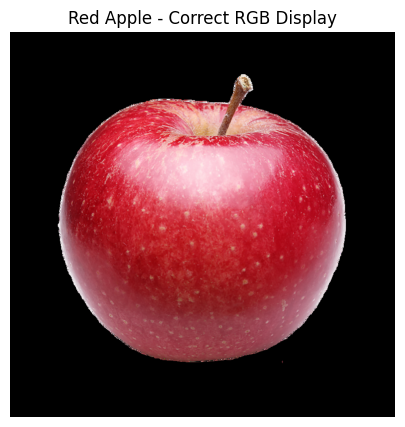

In [4]:
# BGR image lai RGB ma convert gareko for correct matplotlib display
red_apple_rgb = cv2.cvtColor(red_apple, cv2.COLOR_BGR2RGB)

# Correct RGB image display garne
plt.imshow(red_apple_rgb)
plt.title("Red Apple - Correct RGB Display")
plt.axis("off")
plt.show()

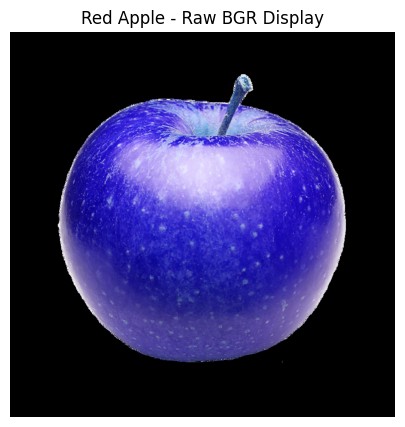

In [6]:
# Raw BGR image directly matplotlib ma display gareko
plt.imshow(red_apple)
plt.title("Red Apple - Raw BGR Display")
plt.axis("off")
plt.show()

### Observation and Explanation

The image was loaded using OpenCV `cv2.imread()`, which reads images in BGR (Blue, Green, Red) channel order by default.

When the image was converted from BGR to RGB using `cv2.cvtColor()`, the apple appeared with its correct natural red color.

However, when the raw BGR image was directly displayed using Matplotlib, the red apple appeared blue. This happens because Matplotlib expects images in RGB format, but OpenCV provides images in BGR format.

Due to the channel order mismatch, the Red and Blue channels are swapped during visualization.

### Conclusion

OpenCV uses BGR format while most visualization libraries use RGB format. Therefore, BGR images should be converted to RGB before displaying them using Matplotlib.

### Question 2

Convert `red_apple.png` image from BGR color space to HSV color space.

Visualize the Hue (H), Saturation (S), and Value (V) channels separately as grayscale images.

Analyze which HSV channel provides the best separation between the fruit and the black background.

In [7]:
# Red apple image lai HSV color space ma convert gareko
red_apple_hsv = cv2.cvtColor(red_apple, cv2.COLOR_BGR2HSV)

# HSV channels separate garne
H, S, V = cv2.split(red_apple_hsv)

# HSV channels ko shape check garne
print("Hue channel shape:", H.shape)
print("Saturation channel shape:", S.shape)
print("Value channel shape:", V.shape)

Hue channel shape: (894, 894)
Saturation channel shape: (894, 894)
Value channel shape: (894, 894)


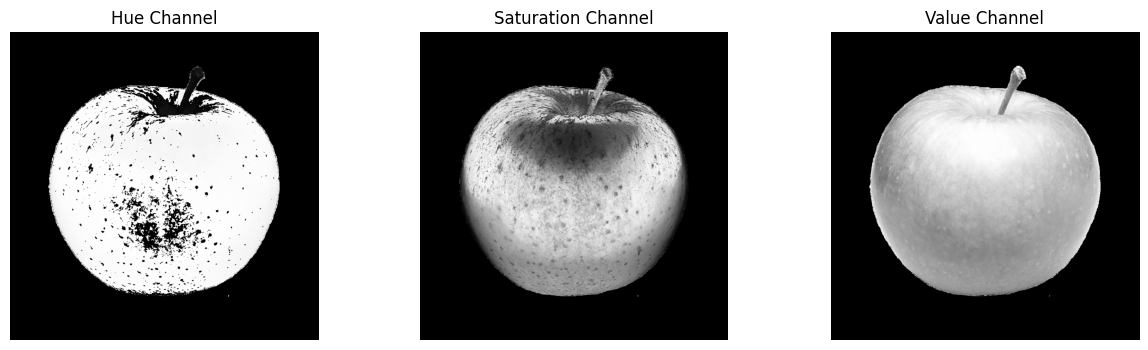

In [8]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(H, cmap="gray")
plt.title("Hue Channel")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(S, cmap="gray")
plt.title("Saturation Channel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(V, cmap="gray")
plt.title("Value Channel")
plt.axis("off")

plt.show()

### Observation and Explanation

The red apple image was converted from BGR color space to HSV color space. The HSV image was separated into three different channels: Hue, Saturation, and Value.

### Hue Channel

The Hue channel represents the actual color information of the image. The apple region shows different grayscale intensity compared to the black background because the Hue values represent different colors.

### Saturation Channel

The Saturation channel represents the purity or intensity of the color. The apple has high saturation because of its strong red color, while the black background has low saturation.

### Value Channel

The Value channel represents the brightness information of the image. It shows the difference between bright and dark regions but does not contain color information.

### Best Channel for Fruit Separation

The Saturation channel provides the best separation between the red apple and the black background because the apple has high color intensity while the background has low intensity.

### Conclusion

HSV color space is useful for fruit segmentation because it separates color information from brightness. Hue and Saturation channels are more useful than RGB channels when detecting fruits under different lighting conditions.

### Question 3

Perform color masking to isolate the red apple using HSV color space.

Red color wraps around the Hue axis in HSV, so two different Hue ranges are required:

- Lower red range: Hue 0-10
- Upper red range: Hue 170-180

Create two masks using `cv2.inRange()` and combine them using `cv2.bitwise_or()`.

Display:

1. Original image
2. Binary mask
3. Masked red apple result

In [9]:
red_apple_hsv = cv2.cvtColor(red_apple, cv2.COLOR_BGR2HSV)

# Lower red color range define gareko
lower_red1 = np.array([0, 100, 50])
upper_red1 = np.array([10, 255, 255])

# Upper red color range define gareko
lower_red2 = np.array([170, 100, 50])
upper_red2 = np.array([180, 255, 255])

# Duita red range ko mask create gareko
mask1 = cv2.inRange(red_apple_hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(red_apple_hsv, lower_red2, upper_red2)

# Duita mask combine gareko
red_mask = cv2.bitwise_or(mask1, mask2)

# Mask apply garera red apple extract gareko
masked_red_apple = cv2.bitwise_and(red_apple, red_apple, mask=red_mask)

print("Masking completed")

Masking completed


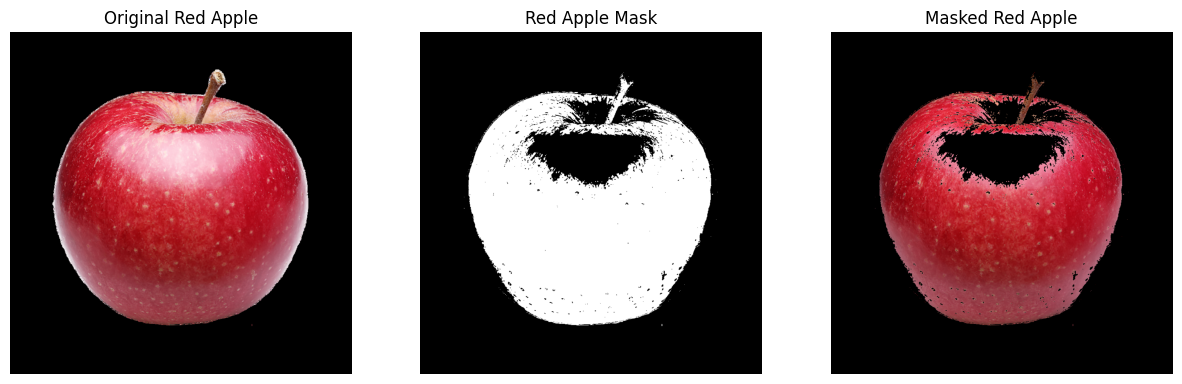

In [10]:
# Original, mask, ra masked result side by side display gareko

plt.figure(figsize=(15, 5))

# Original RGB image
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(red_apple, cv2.COLOR_BGR2RGB))
plt.title("Original Red Apple")
plt.axis("off")

# Binary mask
plt.subplot(1, 3, 2)
plt.imshow(red_mask, cmap="gray")
plt.title("Red Apple Mask")
plt.axis("off")

# Masked result
plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(masked_red_apple, cv2.COLOR_BGR2RGB))
plt.title("Masked Red Apple")
plt.axis("off")

plt.show()

### Observation and Explanation

HSV color masking was applied to isolate the red apple from the background.

Since red color appears at both ends of the Hue range in HSV, two separate masks were created:

- Lower red range: Hue 0-10
- Upper red range: Hue 170-180

Both masks were combined using `cv2.bitwise_or()` to create the final red apple mask.

### Mask Result

The white region in the binary mask represents pixels detected as red, while the black region represents pixels rejected from the color range.

The final masked image successfully extracts the red apple from the background.

### Limitation

Some regions such as bright reflections and highlights may not be detected because they have low saturation and appear closer to white color. Since HSV masking mainly depends on Hue and Saturation values, these regions can be removed from the mask.

### Conclusion

HSV thresholding is effective for isolating fruits based on color, but threshold values may need adjustment depending on lighting conditions and surface reflections.

### Question 4

Repeat HSV color masking for:

- green_apple.png
- banana.png
- lime.png

Find suitable HSV threshold ranges for each fruit.

Record the working HSV ranges in a markdown table:

| Fruit | H_min | H_max | S_min | S_max | V_min | V_max |
|------|------|------|------|------|------|------|
| Green Apple | | | | | | |
| Banana | | | | | | |
| Lime | | | | | | |

The HSV values are selected based on the fruit color distribution.

In [11]:
def create_hsv_mask(image, lower_range, upper_range):
    hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    
    # Given HSV range anusar mask create gareko
    mask = cv2.inRange(hsv_image, lower_range, upper_range)
    
    # Mask apply gareko
    result = cv2.bitwise_and(image, image, mask=mask)
    
    return mask, result

In [13]:
# Required fruit images load garne
green_apple = load_image("green_apple.png")
banana = load_image("banana.png")
lime = load_image("lime.png")

print("Images loaded")

Images loaded


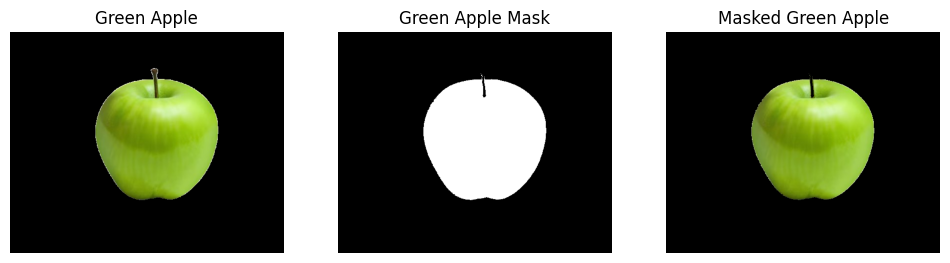

In [14]:
# Green apple ko HSV range define gareko
green_lower = np.array([35, 50, 40])
green_upper = np.array([85, 255, 255])

# Mask create gareko
green_mask, green_result = create_hsv_mask(
    green_apple,
    green_lower,
    green_upper
)

# Result display gareko
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(green_apple, cv2.COLOR_BGR2RGB))
plt.title("Green Apple")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(green_mask, cmap="gray")
plt.title("Green Apple Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(green_result, cv2.COLOR_BGR2RGB))
plt.title("Masked Green Apple")
plt.axis("off")

plt.show()

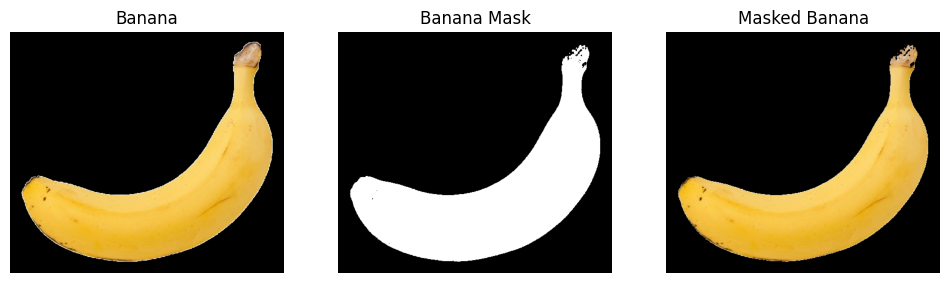

In [15]:
# Banana ko HSV range define gareko
banana_lower = np.array([15, 40, 40])
banana_upper = np.array([40, 255, 255])

# Mask create gareko
banana_mask, banana_result = create_hsv_mask(
    banana,
    banana_lower,
    banana_upper
)

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(banana, cv2.COLOR_BGR2RGB))
plt.title("Banana")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(banana_mask, cmap="gray")
plt.title("Banana Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(banana_result, cv2.COLOR_BGR2RGB))
plt.title("Masked Banana")
plt.axis("off")

plt.show()

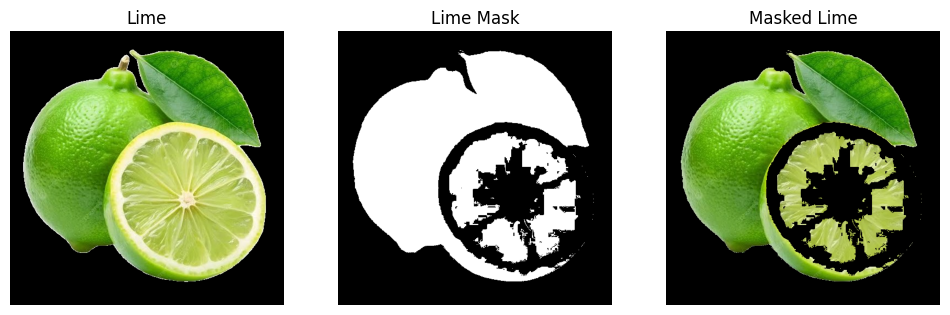

In [16]:
# Lime ko HSV range define gareko
lime_lower = np.array([35, 40, 40])
lime_upper = np.array([90, 255, 255])

# Mask create gareko
lime_mask, lime_result = create_hsv_mask(
    lime,
    lime_lower,
    lime_upper
)

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(lime, cv2.COLOR_BGR2RGB))
plt.title("Lime")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(lime_mask, cmap="gray")
plt.title("Lime Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(lime_result, cv2.COLOR_BGR2RGB))
plt.title("Masked Lime")
plt.axis("off")

plt.show()

### HSV Working Range Table

The following HSV ranges were used for color-based fruit segmentation.

| Fruit | H_min | H_max | S_min | S_max | V_min | V_max |
|------|------|------|------|------|------|------|
| Green Apple | 35 | 85 | 50 | 255 | 40 | 255 |
| Banana | 15 | 40 | 40 | 255 | 40 | 255 |
| Lime | 35 | 90 | 40 | 255 | 40 | 255 |

### Observation

The HSV ranges were selected based on the dominant color information of each fruit.

- Green apple produced a clean mask because its color was mostly uniform.
- Banana segmentation detected the yellow body but removed brown regions because they fall outside the selected HSV range.
- Lime outer skin was detected well, but inner sliced regions were missed because their color and saturation values were different.

### Conclusion

HSV masking works effectively for fruits with consistent color. However, fruits with multiple colors, shadows, highlights, or texture variations require more adaptive thresholding or additional image processing techniques.

### Question 5

Apply manual brightness and contrast adjustment to the banana image.

Parameters:

- Alpha (contrast) = 1.3
- Beta (brightness) = 20

Perform the operation using NumPy:

new_image = alpha * image + beta

The output values should be clipped to the range [0,255] and converted to uint8.

Compare the result with OpenCV's `cv2.convertScaleAbs()`.

Analyze whether brightness adjustment improves HSV color masking reliability.

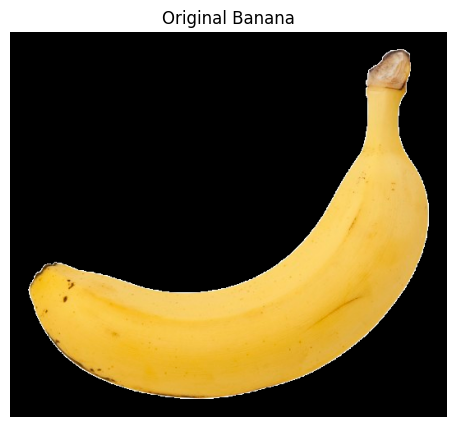

In [17]:
# Banana image load gareko
banana = load_image("banana.png")

# Original banana display gareko
display_rgb(banana, "Original Banana")

In [18]:
# Contrast ra brightness parameter define gareko
alpha = 1.3
beta = 20

# NumPy bata brightness ra contrast adjust gareko
banana_manual = alpha * banana + beta

# Pixel values lai valid range ma clip gareko
banana_manual = np.clip(banana_manual, 0, 255)

# Image lai uint8 format ma convert gareko
banana_manual = banana_manual.astype(np.uint8)

print("Manual adjustment completed")

Manual adjustment completed


In [19]:
# OpenCV built-in brightness and contrast adjustment
banana_cv = cv2.convertScaleAbs(
    banana,
    alpha=alpha,
    beta=beta
)

print("OpenCV adjustment completed")

OpenCV adjustment completed


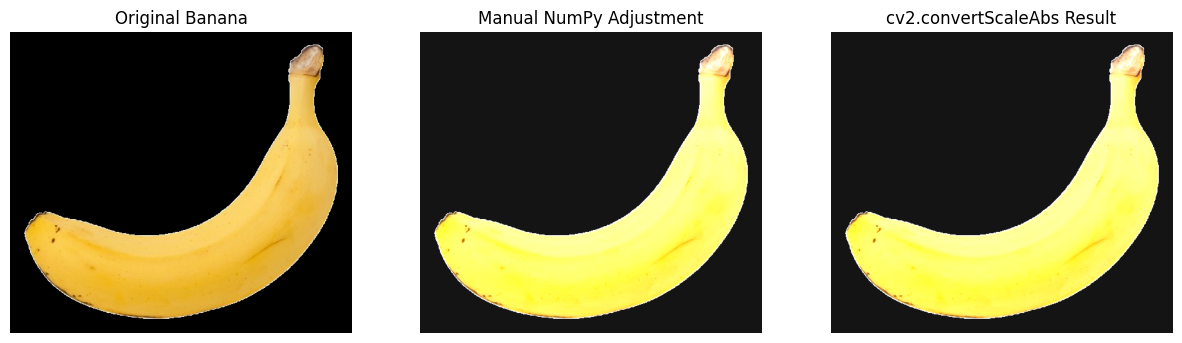

In [20]:
plt.figure(figsize=(15,5))

# Original image
plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(banana, cv2.COLOR_BGR2RGB))
plt.title("Original Banana")
plt.axis("off")

# Manual NumPy result
plt.subplot(1,3,2)
plt.imshow(cv2.cvtColor(banana_manual, cv2.COLOR_BGR2RGB))
plt.title("Manual NumPy Adjustment")
plt.axis("off")

# OpenCV result
plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(banana_cv, cv2.COLOR_BGR2RGB))
plt.title("cv2.convertScaleAbs Result")
plt.axis("off")

plt.show()

In [22]:
# Manual ra OpenCV result ko difference calculate gareko
difference = cv2.absdiff(banana_manual, banana_cv)

# Mean absolute difference calculate gareko
mean_difference = np.mean(difference)

print("Mean Absolute Difference:", mean_difference)

Mean Absolute Difference: 0.056814477558501796


### Observation and Explanation

Brightness and contrast adjustment was applied to the banana image using two different methods:

1. Manual NumPy implementation
2. OpenCV `cv2.convertScaleAbs()` function

The transformation used:

- Alpha (contrast) = 1.3
- Beta (brightness) = 20

Both methods increased the brightness and contrast of the banana image.

### Comparison

The Mean Absolute Difference between the manually adjusted image and OpenCV adjusted image was:

0.056814477558501796

This value is very small compared to the pixel intensity range of 0-255. Therefore, both methods produced almost identical results.

The small difference is caused by minor rounding and datatype conversion differences during pixel calculation.

### Effect on HSV Masking

Brightness adjustment can improve HSV segmentation when the original image is dark because the fruit becomes more visible and its color information becomes easier to detect.

However, excessive brightness can reduce mask accuracy because strong highlights may decrease saturation and move outside the selected HSV threshold range.

### Conclusion

Manual NumPy adjustment and `cv2.convertScaleAbs()` provide nearly identical results. Proper brightness and contrast correction can improve HSV-based fruit segmentation under variable lighting conditions.

### Question 6

Explain why HSV works better than RGB for fruit color segmentation.

Also explain when HSV segmentation can fail.

Example case:

- Very dark purple grape
- Blueberry

Analyze the limitations of HSV-based color segmentation.

### Reflection: Why HSV is Better than RGB

HSV color space works better than RGB for fruit segmentation because it separates color information from brightness.

In RGB, color and lighting information are mixed together. If the lighting changes, the RGB values also change, which makes object detection difficult.

HSV has three components:

- Hue: Represents the actual color of the object.
- Saturation: Represents how strong or pure the color is.
- Value: Represents the brightness of the image.

For fruit detection, Hue and Saturation are more useful because they help identify the fruit color even when brightness changes.

### Limitations of HSV

HSV segmentation can fail in some cases:

- Very dark fruits like blueberries or dark purple grapes may have low color information.
- Strong light reflections can make some fruit areas appear white.
- Background colors similar to the fruit can create incorrect detection.
- Fruits with multiple colors may need different HSV ranges.

### Conclusion

HSV is a better choice than RGB for color-based fruit segmentation because it focuses on color information instead of only pixel values. However, threshold values need to be adjusted depending on lighting and fruit appearance.

## Part B - Histograms & Filtering

### Question 1

Load `strawberry.png` as a grayscale image.

Plot its histogram.

Analyze the histogram and answer:

- Is the image well exposed?
- What does the histogram distribution tell about the image contrast?

Image shape: (590, 423)


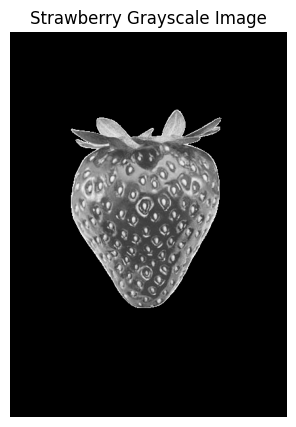

In [23]:
# Strawberry image grayscale ma load gareko
strawberry_gray = cv2.imread(
    os.path.join(DATA_PATH, "strawberry.png"),
    cv2.IMREAD_GRAYSCALE
)

# Image successfully load bhayo ki check gareko
print("Image shape:", strawberry_gray.shape)

# Grayscale image display gareko
plt.imshow(strawberry_gray, cmap="gray")
plt.title("Strawberry Grayscale Image")
plt.axis("off")
plt.show()

In [26]:
# Strawberry image check garne
print(strawberry_gray)

# Minimum ra maximum pixel value check garne
print("Min pixel value:", strawberry_gray.min())
print("Max pixel value:", strawberry_gray.max())

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
Min pixel value: 0
Max pixel value: 255


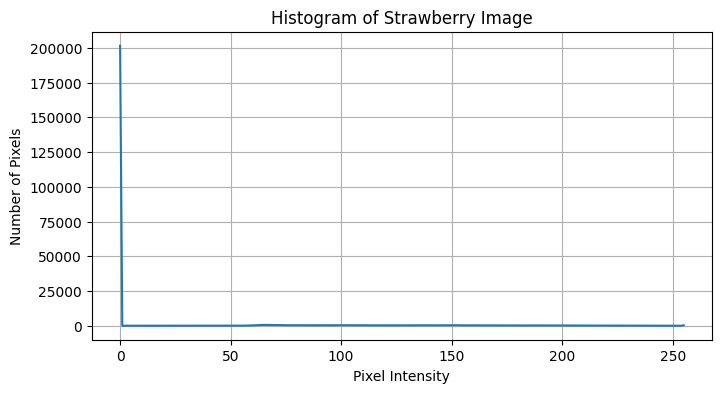

In [25]:
# Histogram calculate garne
histogram = cv2.calcHist(
    [strawberry_gray],
    [0],
    None,
    [256],
    [0, 256]
)

# Histogram lai flatten garne
histogram = histogram.ravel()

# Histogram display garne
plt.figure(figsize=(8,4))

plt.plot(histogram)

plt.title("Histogram of Strawberry Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")

plt.grid()
plt.show()

### Observation and Explanation

The strawberry image was converted into grayscale and its histogram was plotted.

The histogram shows a very high peak near pixel intensity 0. This happens because the image contains a large black background, and many pixels have intensity value close to 0.

The strawberry region contains different grayscale values between dark and bright areas. These values represent the fruit texture, seeds, and light reflections.

### Exposure and Contrast Analysis

The image is properly exposed because the strawberry details are visible and the pixel values are distributed across a wide range.

However, the histogram is dominated by the black background, which makes the contrast analysis of the fruit itself difficult.

The large intensity range indicates that the image contains both dark and bright regions, giving it reasonable contrast.

### Conclusion

The histogram helps understand the brightness distribution of an image. In this case, the large black background creates a strong peak at intensity 0, while the remaining pixels represent the strawberry details.

### Question 2

Apply histogram equalization techniques to improve the image contrast.

Perform the following operations:

- Original grayscale image
- Global Histogram Equalization
- CLAHE with `clipLimit = 2.0`
- CLAHE with `clipLimit = 8.0`

Display all four images side by side.

Compare the results and identify which method provides better image enhancement for fruit segmentation.

In [27]:
# Global histogram equalization apply gareko
equalized = cv2.equalizeHist(strawberry_gray)

# CLAHE object create garne with clipLimit 2.0
clahe_2 = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# CLAHE object create garne with clipLimit 8.0
clahe_8 = cv2.createCLAHE(
    clipLimit=8.0,
    tileGridSize=(8, 8)
)

# CLAHE apply garne
clahe_img_2 = clahe_2.apply(strawberry_gray)
clahe_img_8 = clahe_8.apply(strawberry_gray)

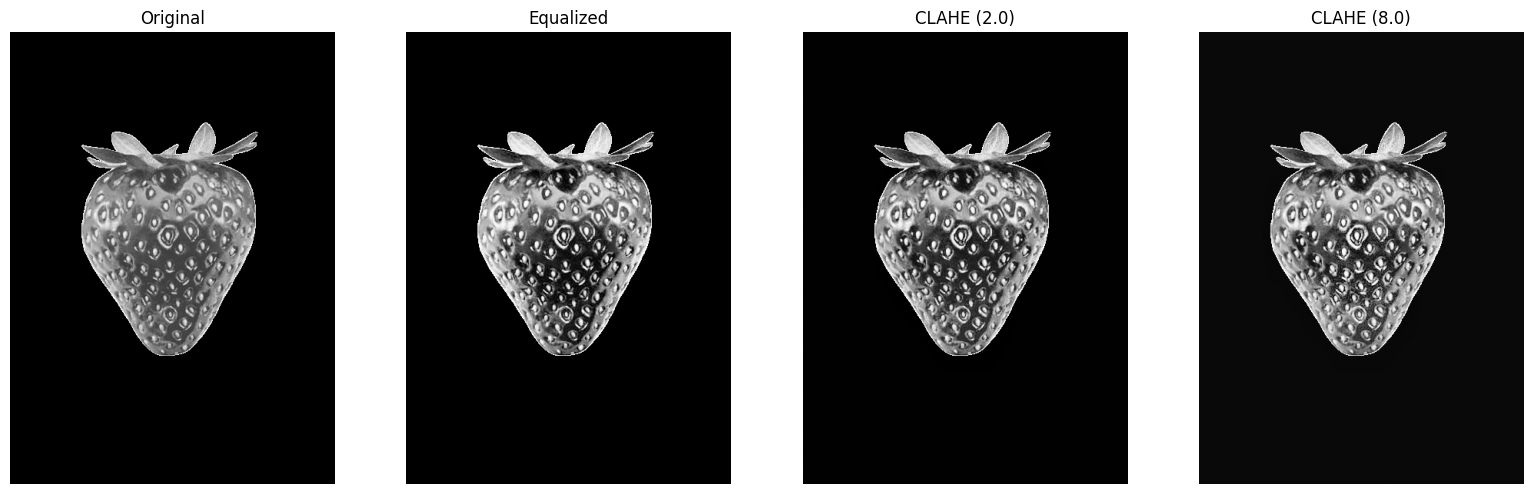

In [28]:
# Sabai images compare gareko
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(strawberry_gray, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Equalized")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(clahe_img_2, cmap="gray")
plt.title("CLAHE (2.0)")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(clahe_img_8, cmap="gray")
plt.title("CLAHE (8.0)")
plt.axis("off")

plt.tight_layout()
plt.show()

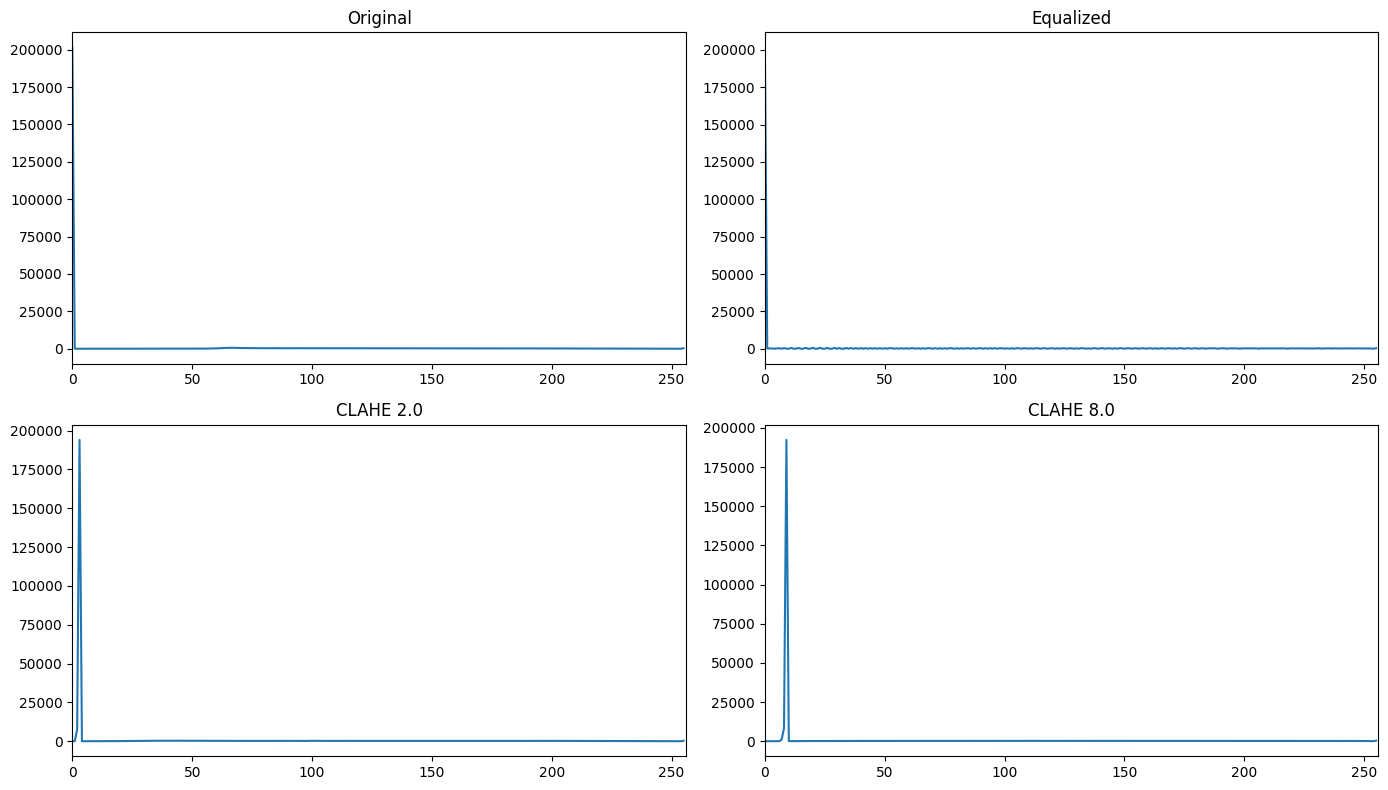

In [29]:
# Histogram compare gareko
images = [
    strawberry_gray,
    equalized,
    clahe_img_2,
    clahe_img_8
]

titles = [
    "Original",
    "Equalized",
    "CLAHE 2.0",
    "CLAHE 8.0"
]

plt.figure(figsize=(14, 8))

for i in range(4):
    plt.subplot(2, 2, i + 1)

    hist = cv2.calcHist(
        [images[i]],
        [0],
        None,
        [256],
        [0, 256]
    )

    plt.plot(hist)
    plt.title(titles[i])
    plt.xlim([0, 256])

plt.tight_layout()
plt.show()

### Observation

The original grayscale image has normal contrast, but some details are not clearly visible.

After applying global histogram equalization, the overall contrast increased. However, the image became too bright and some regions looked over-enhanced.

CLAHE with `clipLimit = 2.0` improved the local contrast while preserving the natural appearance of the strawberry.

CLAHE with `clipLimit = 8.0` increased the contrast further, but some regions appeared slightly stronger than necessary.

### Comparison

- **Original:** Natural appearance with normal contrast.
- **Equalized:** High contrast but over-enhanced in some areas.
- **CLAHE (2.0):** Better local contrast with clear fruit details.
- **CLAHE (8.0):** Stronger contrast than CLAHE (2.0), but slightly more aggressive.

### Which Method Works Best?

Among all methods, **CLAHE with clipLimit = 2.0** provides the best result. It improves image details without introducing excessive brightness or contrast.

A better contrast image usually helps color segmentation because important fruit details become easier to distinguish.

### Conclusion

CLAHE is more effective than global histogram equalization for this image. It enhances local contrast while preserving the natural appearance of the fruit, making it more suitable for further image processing tasks.

### Question 3

Add Gaussian noise to `orange.png` using NumPy with:

- Mean = 0
- Standard deviation = 25

Apply the following filters to the noisy image:

- Gaussian Blur
- Median Filter
- Bilateral Filter

Display all images side by side and compare the results.

Identify which filter removes the noise best while preserving the fruit edges.

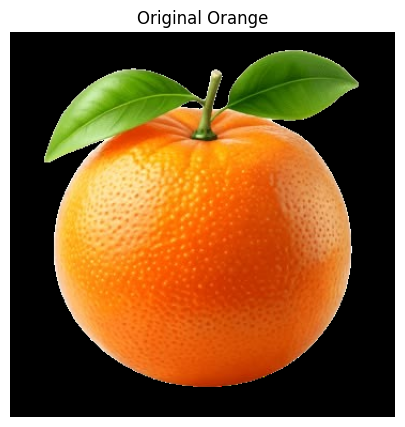

In [30]:
# Orange image load gareko
orange = load_image("orange.png")

# BGR bata RGB ma convert gareko
orange_rgb = cv2.cvtColor(orange, cv2.COLOR_BGR2RGB)

plt.imshow(orange_rgb)
plt.title("Original Orange")
plt.axis("off")
plt.show()

In [31]:
# Gaussian noise generate gareko
mean = 0
std = 25

noise = np.random.normal(
    mean,
    std,
    orange.shape
).astype(np.float32)

# Original image float32 ma convert gareko
orange_float = orange.astype(np.float32)

# Noise add garne
noisy_orange = orange_float + noise

# Pixel value valid range ma rakhne
noisy_orange = np.clip(noisy_orange, 0, 255)

# uint8 ma convert gareko
noisy_orange = noisy_orange.astype(np.uint8)

In [32]:
# Gaussian Blur apply gareko
gaussian_result = cv2.GaussianBlur(
    noisy_orange,
    (5, 5),
    0
)

# Median filter apply gareko
median_result = cv2.medianBlur(
    noisy_orange,
    5
)

# Bilateral filter apply gareko
bilateral_result = cv2.bilateralFilter(
    noisy_orange,
    9,
    75,
    75
)

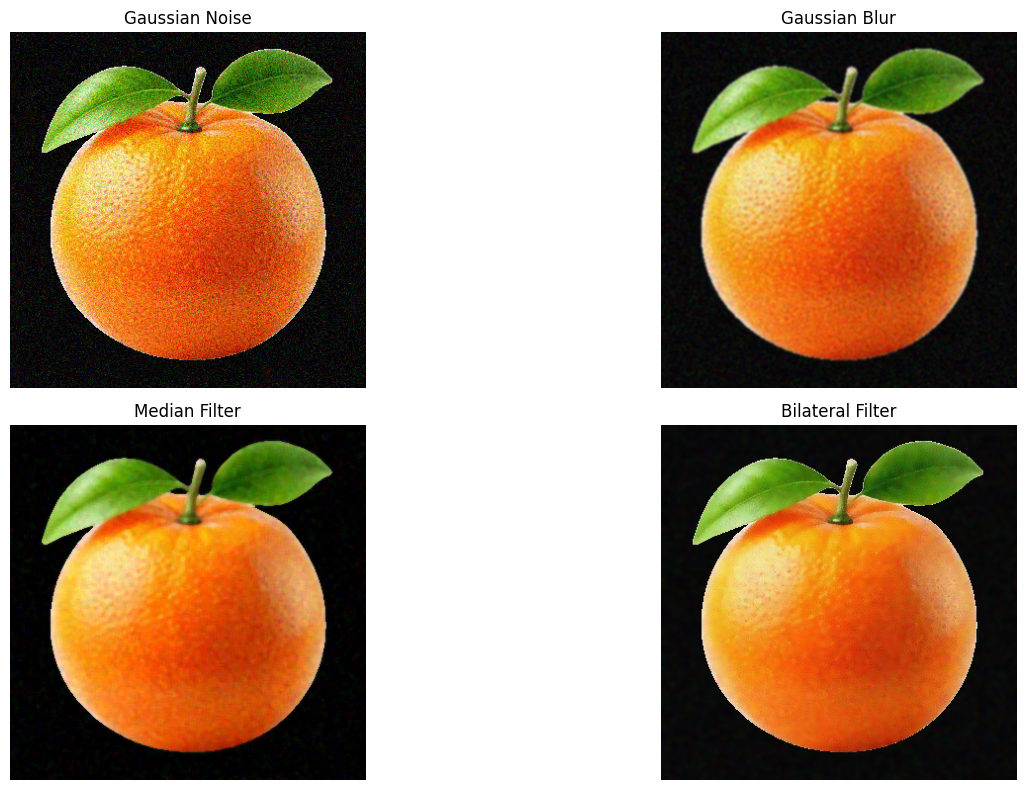

In [33]:
# Sabai result compare gareko
plt.figure(figsize=(16,8))

plt.subplot(2,2,1)
plt.imshow(cv2.cvtColor(noisy_orange, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(cv2.cvtColor(gaussian_result, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(cv2.cvtColor(median_result, cv2.COLOR_BGR2RGB))
plt.title("Median Filter")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(cv2.cvtColor(bilateral_result, cv2.COLOR_BGR2RGB))
plt.title("Bilateral Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

Gaussian noise was added to the orange image to simulate a noisy camera image.

Three different filters were applied to reduce the noise:

- Gaussian Blur
- Median Filter
- Bilateral Filter

### Comparison

**Gaussian Blur**

Gaussian Blur reduced the noise, but it also blurred the edges of the orange and leaves.

**Median Filter**

Median Filter removed most of the noise and preserved the edges better than Gaussian Blur. However, some fine texture was slightly reduced.

**Bilateral Filter**

Bilateral Filter removed the noise while keeping the fruit edges sharp. The object boundaries remained clear and the image looked more natural.

### Best Filter

Among all three filters, **Bilateral Filter** produced the best result because it reduced the noise while preserving important edges.

### Conclusion

Different filters have different strengths. Gaussian Blur is simple but smooths edges. Median Filter is effective for noise removal, while Bilateral Filter provides the best balance between noise reduction and edge preservation, making it suitable for computer vision applications.

### Question 4

Implement a 2D convolution function (`conv2d`) from scratch.

Apply a Sobel X kernel to the grayscale banana image.

Compare the manually computed result with OpenCV's `cv2.filter2D()`.

Calculate the Mean Absolute Difference (MAD) between both outputs and explain any difference.

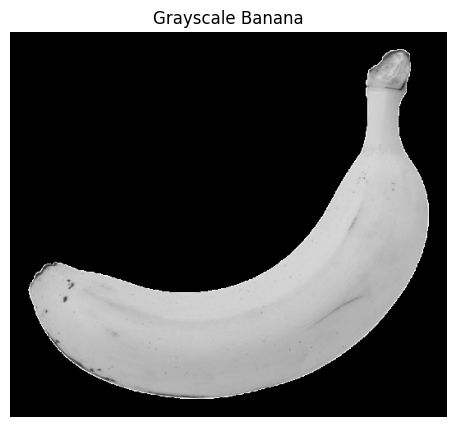

In [34]:
# Banana image grayscale ma load gareko
banana_gray = cv2.imread(
    os.path.join(DATA_PATH, "banana.png"),
    cv2.IMREAD_GRAYSCALE
)

# Image display gareko
plt.imshow(banana_gray, cmap="gray")
plt.title("Grayscale Banana")
plt.axis("off")
plt.show()

In [35]:
# Sobel X kernel define gareko
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

print(sobel_x)

[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]


In [36]:
# conv2d function from scratch create gareko
def conv2d(image, kernel):

    # Image size read gareko
    image_height, image_width = image.shape

    # Kernel size read gareko
    kernel_height, kernel_width = kernel.shape

    # Padding size calculate gareko
    pad_h = kernel_height // 2
    pad_w = kernel_width // 2

    # Zero padding add gareko
    padded = np.pad(
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode="constant"
    )

    # Output image initialize gareko
    output = np.zeros_like(image, dtype=np.float32)

    # Convolution perform gareko
    for y in range(image_height):
        for x in range(image_width):

            # Current region extract gareko
            region = padded[
                y:y + kernel_height,
                x:x + kernel_width
            ]

            # Kernel multiplication ra summation gareko
            output[y, x] = np.sum(region * kernel)

    return output

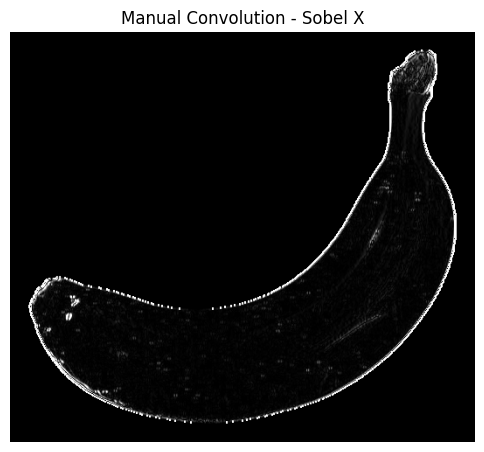

In [37]:
# Manual convolution apply gareko
manual_sobel = conv2d(
    banana_gray,
    sobel_x
)

# Absolute value calculate gareko
manual_sobel = np.abs(manual_sobel)

# Pixel values valid range ma clip gareko
manual_sobel = np.clip(
    manual_sobel,
    0,
    255
)

# uint8 ma convert gareko
manual_sobel = manual_sobel.astype(np.uint8)

# Result display gareko
plt.figure(figsize=(6, 6))

plt.imshow(manual_sobel, cmap="gray")
plt.title("Manual Convolution - Sobel X")
plt.axis("off")

plt.show()

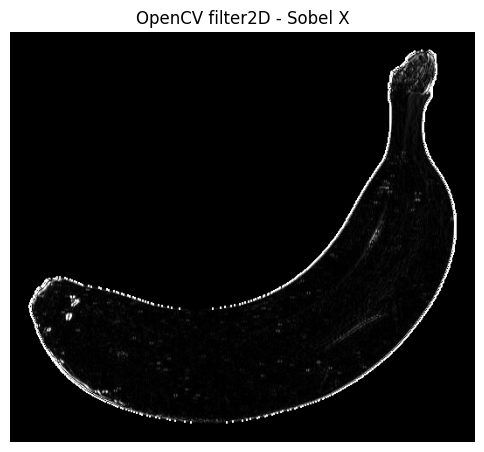

In [38]:
# OpenCV filter2D apply gareko
opencv_sobel = cv2.filter2D(
    banana_gray,
    ddepth=cv2.CV_32F,
    kernel=sobel_x
)

# Absolute value calculate gareko
opencv_sobel = np.abs(opencv_sobel)

# Pixel values valid range ma clip gareko
opencv_sobel = np.clip(
    opencv_sobel,
    0,
    255
)

# uint8 ma convert gareko
opencv_sobel = opencv_sobel.astype(np.uint8)

# Result display gareko
plt.figure(figsize=(6, 6))

plt.imshow(opencv_sobel, cmap="gray")
plt.title("OpenCV filter2D - Sobel X")
plt.axis("off")

plt.show()

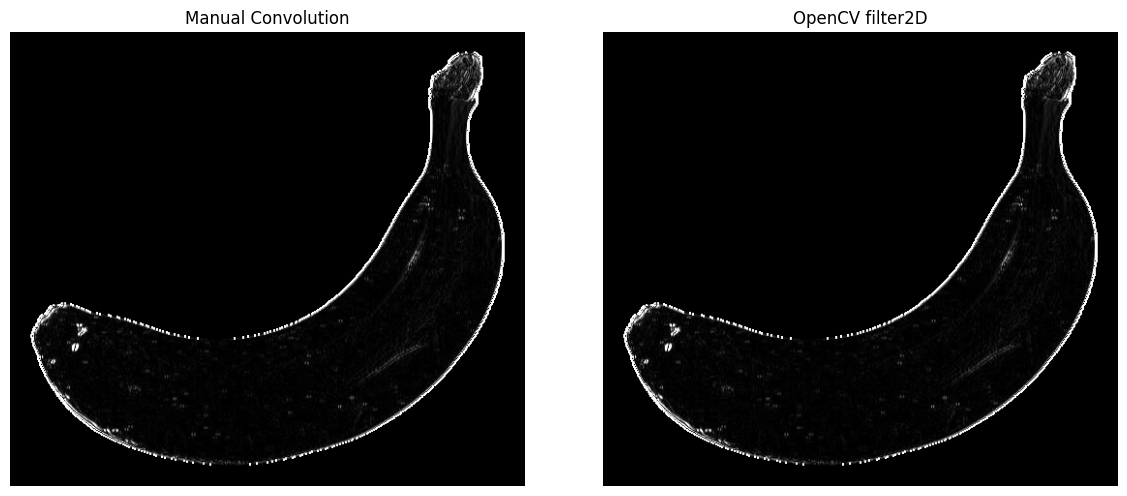

In [39]:
# Manual ra OpenCV result side by side compare gareko
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(manual_sobel, cmap="gray")
plt.title("Manual Convolution")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(opencv_sobel, cmap="gray")
plt.title("OpenCV filter2D")
plt.axis("off")

plt.tight_layout()
plt.show()

In [40]:
# Mean Absolute Difference calculate gareko
mad = np.mean(
    np.abs(
        manual_sobel.astype(np.float32) -
        opencv_sobel.astype(np.float32)
    )
)

print("Mean Absolute Difference:", mad)

Mean Absolute Difference: 0.0


### Observation

The Sobel X operator was implemented manually using the `conv2d()` function and compared with OpenCV's `cv2.filter2D()`.

Both methods detected the vertical edges of the banana successfully. The manual implementation produced almost the same output as the OpenCV implementation.

### Mean Absolute Difference

The Mean Absolute Difference (MAD) between the manual convolution and OpenCV output was **0.0** .

### Explanation

The very small difference shows that the manual implementation works correctly.

Any small difference may occur because of floating-point calculations or pixel value conversion.

### Conclusion

The manual convolution implementation produces results very similar to OpenCV's built-in function, confirming that the custom implementation is correct.

## Part C - Morphology & Mask Cleanup

### Question 5

Take the banana HSV mask from Part A.

Apply **erosion** using a **5 × 5 kernel**.

Observe how the mask changes after erosion.

In [41]:
# 5x5 kernel create gareko
kernel = np.ones((5, 5), dtype=np.uint8)

# Banana mask ma erosion apply gareko
banana_eroded = cv2.erode(
    banana_mask,
    kernel,
    iterations=1
)

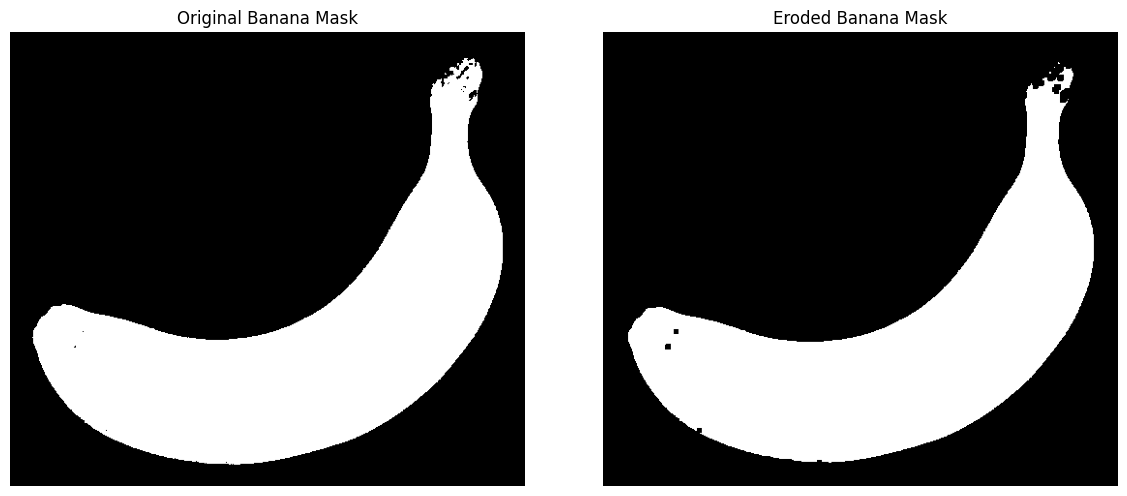

In [42]:
# Original mask ra eroded mask display gareko
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(banana_mask, cmap="gray")
plt.title("Original Banana Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(banana_eroded, cmap="gray")
plt.title("Eroded Banana Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

A **5 × 5 kernel** was used to apply erosion to the banana mask.

After erosion, the white region became smaller because pixels around the object boundary were removed.

The thin stem and small edge details were reduced, and some small white regions disappeared completely.

### What Happened to the Mask?

- The banana mask became slightly smaller.
- Object boundaries became thinner.
- Small noisy regions were removed.
- Fine details near the edges were reduced.

### Conclusion

Erosion removes pixels from the object boundary. It is useful for removing small noise, but using a large kernel or too many iterations can remove important parts of the object.

### Question 6

Apply the following morphological operations to the banana mask:

- Erosion
- Opening (Erosion → Dilation)
- Closing (Dilation → Erosion)

Display the following images side by side:

- Raw Mask
- After Erosion
- After Opening
- After Closing

Compare the effect of each operation.

In [43]:
# Opening operation apply gareko
banana_opening = cv2.morphologyEx(
    banana_mask,
    cv2.MORPH_OPEN,
    kernel
)

# Closing operation apply gareko
banana_closing = cv2.morphologyEx(
    banana_mask,
    cv2.MORPH_CLOSE,
    kernel
)

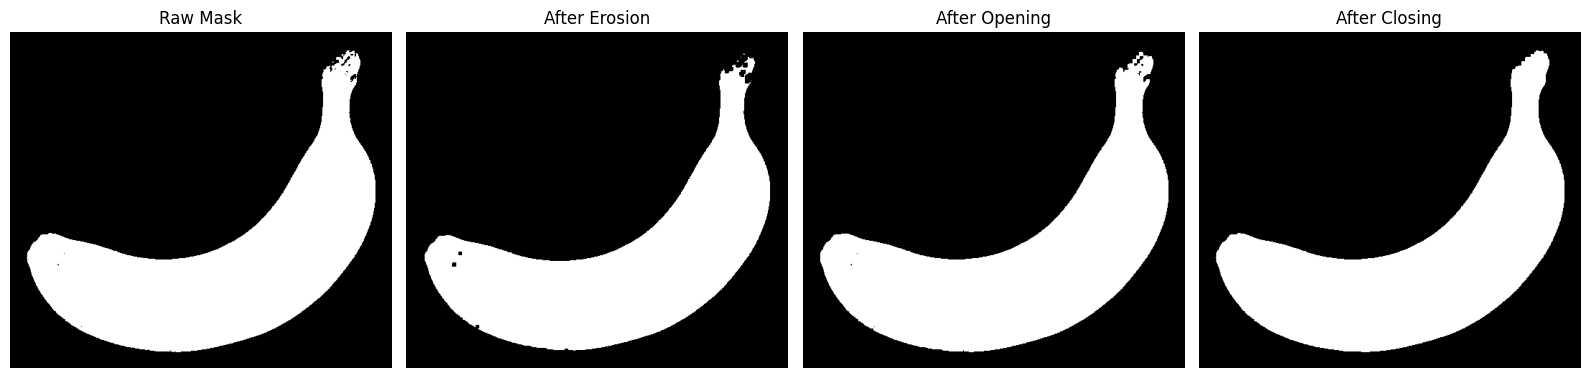

In [44]:
# Sabai masks compare gareko
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(banana_mask, cmap="gray")
plt.title("Raw Mask")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(banana_eroded, cmap="gray")
plt.title("After Erosion")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(banana_opening, cmap="gray")
plt.title("After Opening")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(banana_closing, cmap="gray")
plt.title("After Closing")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

Three morphological operations were applied to the banana mask after the original mask.

### Erosion

Erosion reduced the size of the banana mask by removing pixels from the object boundary.

The thin stem became smaller and some fine details disappeared.

### Opening

Opening removed small noise around the object while keeping the overall banana shape.

The mask became cleaner and smoother than the original mask.

### Closing

Closing filled small holes and gaps inside the banana mask.

The object became more solid, and small breaks in the mask were reduced.

### Comparison

- **Raw Mask:** Original binary mask.
- **Erosion:** Shrinks the object and removes boundary pixels.
- **Opening:** Removes small noise and smooths the object.
- **Closing:** Fills small holes and connects nearby regions.

### Conclusion

Opening is useful for removing small noise from a binary mask.

Closing is useful for filling small holes and improving the completeness of the detected object.

### Question 7

Apply the **Morphological Gradient** operation to the banana mask.

Extract the banana outline and overlay it on the original banana image using **green color**.

Display:

- Morphological Gradient
- Original Image with Green Outline

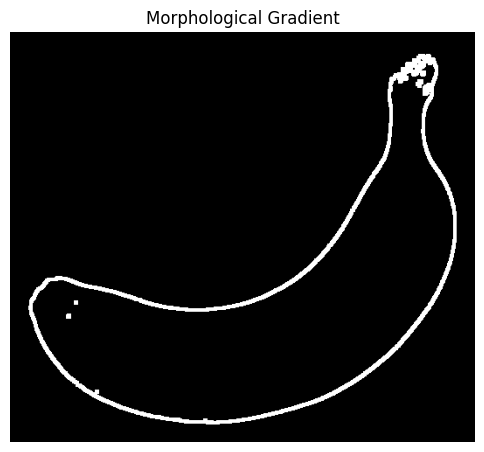

In [45]:
# Morphological gradient apply gareko
banana_gradient = cv2.morphologyEx(
    banana_mask,
    cv2.MORPH_GRADIENT,
    kernel
)

# Gradient image display gareko
plt.figure(figsize=(6, 6))

plt.imshow(banana_gradient, cmap="gray")
plt.title("Morphological Gradient")
plt.axis("off")

plt.show()

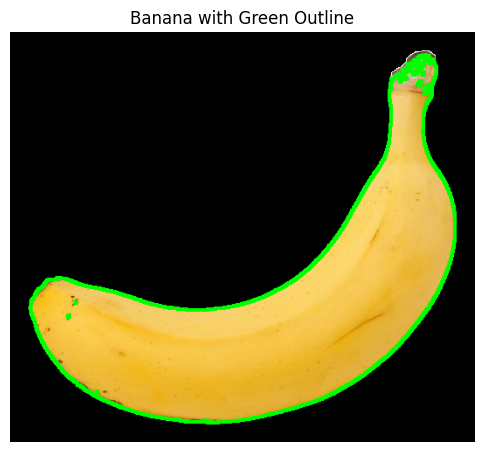

In [46]:
# Original banana image copy gareko
banana_outline = banana.copy()

# Green color ma outline draw gareko
banana_outline[banana_gradient > 0] = (0, 255, 0)

# BGR bata RGB ma convert gareko
banana_outline_rgb = cv2.cvtColor(
    banana_outline,
    cv2.COLOR_BGR2RGB
)

# Result display gareko
plt.figure(figsize=(6, 6))

plt.imshow(banana_outline_rgb)
plt.title("Banana with Green Outline")
plt.axis("off")

plt.show()

### Observation

The Morphological Gradient was applied to the banana mask to extract the object boundary.

The result contains only the outer outline of the banana, while the inner region becomes black.

The extracted boundary was then overlaid on the original banana image using green color.

### Result

The green outline follows the banana boundary accurately and clearly highlights the object shape.

This makes it easier to visualize the detected object boundary on the original image.

### Conclusion

Morphological Gradient is useful for extracting object outlines from a binary mask. It provides a clean boundary that can be used for object visualization and further shape analysis.

### Question 8

Apply morphological operations directly to the original **BGR banana image** instead of the binary mask.

Compare the original image with the processed image.

Describe what happens when morphology is applied to a color image.

In [47]:
# Original BGR image ma opening apply gareko
banana_bgr_opening = cv2.morphologyEx(
    banana,
    cv2.MORPH_OPEN,
    kernel
)

# Original BGR image ma closing apply gareko
banana_bgr_closing = cv2.morphologyEx(
    banana,
    cv2.MORPH_CLOSE,
    kernel
)

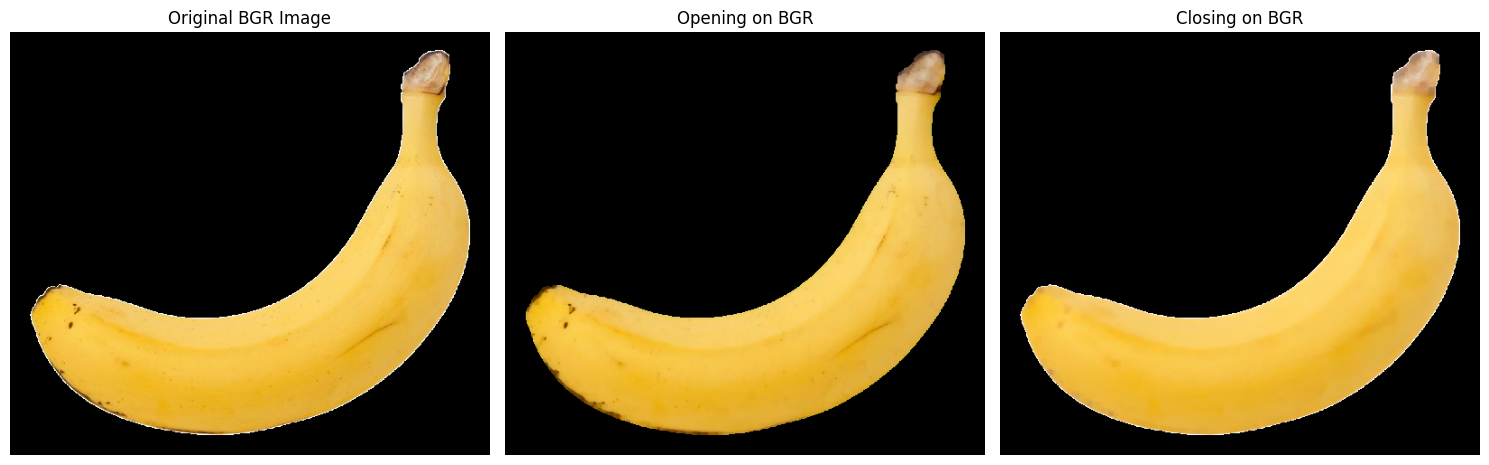

In [48]:
# Display ko lagi RGB ma convert gareko
banana_rgb = cv2.cvtColor(
    banana,
    cv2.COLOR_BGR2RGB
)

banana_open_rgb = cv2.cvtColor(
    banana_bgr_opening,
    cv2.COLOR_BGR2RGB
)

banana_close_rgb = cv2.cvtColor(
    banana_bgr_closing,
    cv2.COLOR_BGR2RGB
)

# Original ra processed images compare gareko
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(banana_rgb)
plt.title("Original BGR Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(banana_open_rgb)
plt.title("Opening on BGR")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(banana_close_rgb)
plt.title("Closing on BGR")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

Morphological operations were applied directly to the original BGR banana image.

Unlike the binary mask, the operations modified the color pixels of the image instead of only changing the object shape.

### Opening on BGR

Opening slightly smoothed the banana surface and reduced some small bright details.

The object edges became smoother, and a few fine textures were removed.

### Closing on BGR

Closing filled some small dark spots and gaps on the banana surface.

The image looked smoother, and small imperfections became less visible.

### Reflection

Morphological operations work best on binary masks because they are designed to process object shapes.

When applied directly to a BGR image, they change the color values of the pixels instead of only modifying the object boundary.

For object segmentation and shape analysis, it is better to apply morphological operations after creating a binary mask.

### Conclusion

Morphological operations can be applied to color images, but they are more effective and meaningful when used on binary masks for computer vision tasks.

### Question 9

Using `morphology.png`, apply the following morphological operations:

- Erosion
- Dilation
- Opening
- Closing
- Top Hat
- Black Hat

Display all six results and identify which operation best isolates the thin strokes.

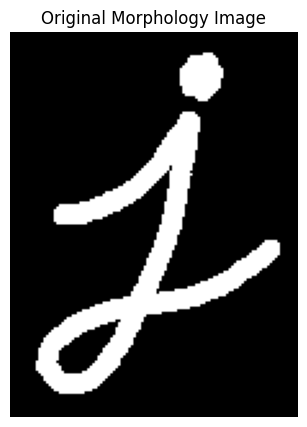

In [49]:
# Morphology demo image grayscale ma load gareko
morphology_img = cv2.imread(
    os.path.join(DATA_PATH, "morphology.png"),
    cv2.IMREAD_GRAYSCALE
)

# Image display gareko
plt.figure(figsize=(5, 5))

plt.imshow(morphology_img, cmap="gray")
plt.title("Original Morphology Image")
plt.axis("off")

plt.show()

In [50]:
# 5x5 kernel create gareko
kernel = np.ones((5, 5), dtype=np.uint8)

# Erosion apply gareko
erosion = cv2.erode(
    morphology_img,
    kernel,
    iterations=1
)

# Dilation apply gareko
dilation = cv2.dilate(
    morphology_img,
    kernel,
    iterations=1
)

# Opening apply gareko
opening = cv2.morphologyEx(
    morphology_img,
    cv2.MORPH_OPEN,
    kernel
)

# Closing apply gareko
closing = cv2.morphologyEx(
    morphology_img,
    cv2.MORPH_CLOSE,
    kernel
)

# Top Hat apply gareko
top_hat = cv2.morphologyEx(
    morphology_img,
    cv2.MORPH_TOPHAT,
    kernel
)

# Black Hat apply gareko
black_hat = cv2.morphologyEx(
    morphology_img,
    cv2.MORPH_BLACKHAT,
    kernel
)

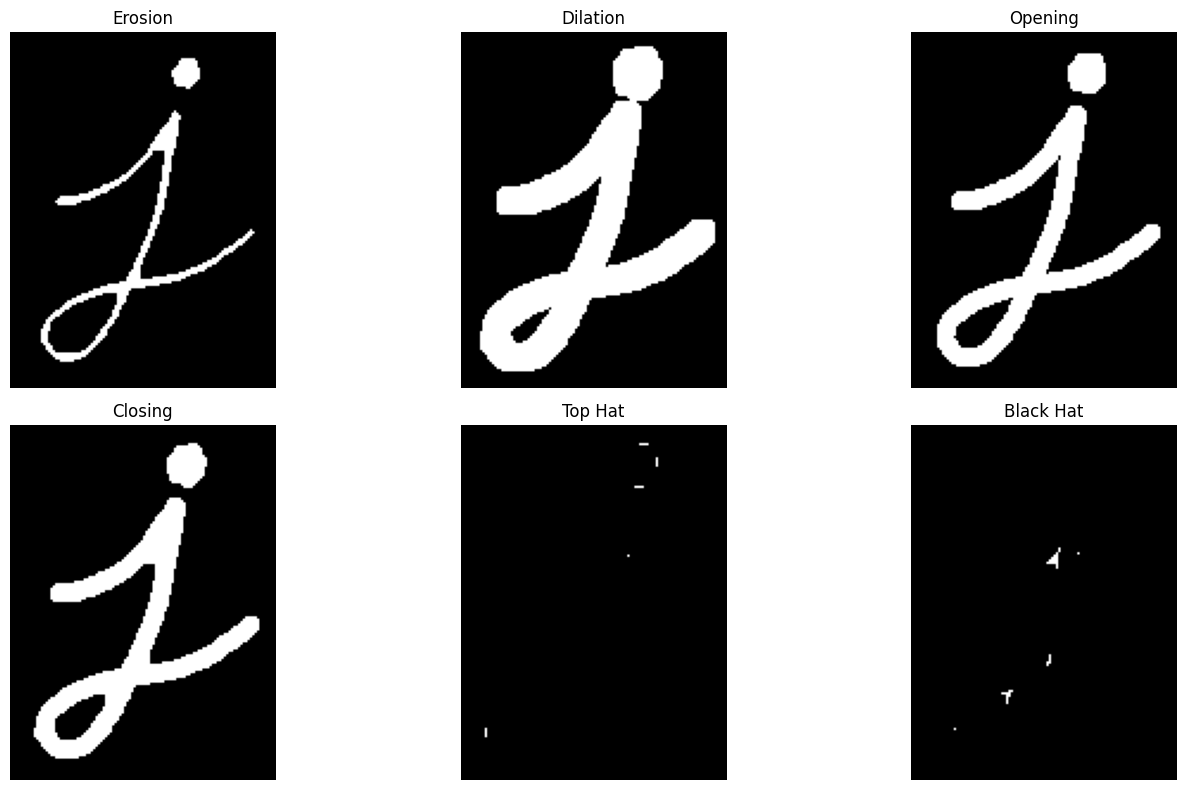

In [51]:
# Sabai morphology results display gareko
titles = [
    "Erosion",
    "Dilation",
    "Opening",
    "Closing",
    "Top Hat",
    "Black Hat"
]

images = [
    erosion,
    dilation,
    opening,
    closing,
    top_hat,
    black_hat
]

plt.figure(figsize=(15, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

Six morphological operations were applied to the morphology image.

### Erosion

Erosion reduced the thickness of the character by removing pixels from the boundary.

### Dilation

Dilation increased the thickness of the character by adding pixels around the boundary.

### Opening

Opening removed small bright details and produced a smoother result while keeping the main character.

### Closing

Closing filled small gaps and made the character more continuous.

### Top Hat

Top Hat highlighted small bright features that were removed by the opening operation.

### Black Hat

Black Hat highlighted small dark regions that were filled during the closing operation.

### Which Operation Isolates the Thin Strokes?

**Top Hat** best isolates the thin bright strokes and fine details. It extracts small bright structures that are different from the surrounding background.

### Conclusion

Each morphological operation has a different purpose. Erosion and dilation modify the object size, opening removes small bright noise, closing fills small gaps, while Top Hat and Black Hat are useful for extracting fine image details.

## Part D - Shape & Feature Detection

### Question 10

Apply Canny Edge Detection to `green_apple.png`.

Use two threshold pairs:

- Low Threshold = 30, High Threshold = 100
- Low Threshold = 100, High Threshold = 200

Compare both edge detection results.

Identify which threshold pair detects the fruit boundary more accurately and explain the stages of the Canny Edge Detection algorithm.

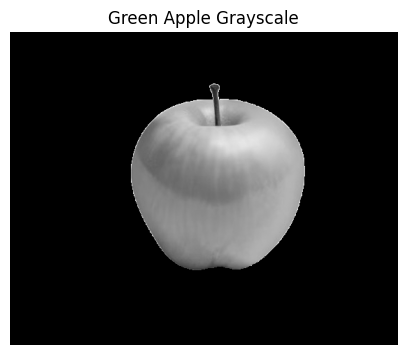

In [52]:
# Green apple image grayscale ma load gareko
green_apple_gray = cv2.imread(
    os.path.join(DATA_PATH, "green_apple.png"),
    cv2.IMREAD_GRAYSCALE
)

# Image display gareko
plt.figure(figsize=(5, 5))

plt.imshow(green_apple_gray, cmap="gray")
plt.title("Green Apple Grayscale")
plt.axis("off")

plt.show()

In [53]:
# Low threshold canny apply gareko
canny_30_100 = cv2.Canny(
    green_apple_gray,
    30,
    100
)

# High threshold canny apply gareko
canny_100_200 = cv2.Canny(
    green_apple_gray,
    100,
    200
)

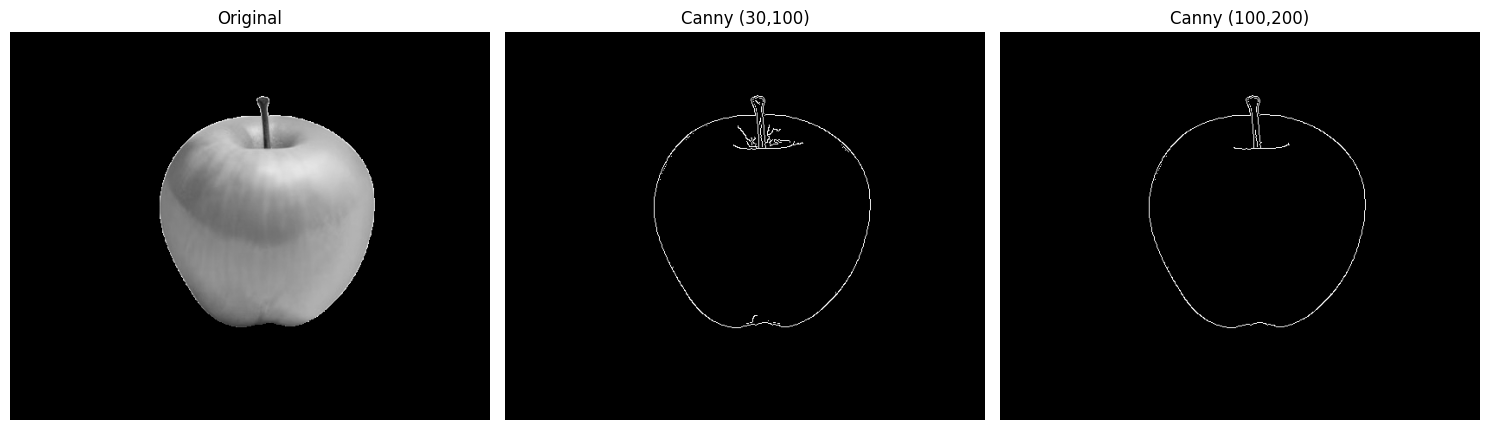

In [54]:
# Original image ra canny outputs display gareko
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(green_apple_gray, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(canny_30_100, cmap="gray")
plt.title("Canny (30,100)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(canny_100_200, cmap="gray")
plt.title("Canny (100,200)")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

Canny Edge Detection was applied to the grayscale green apple image using two different threshold pairs.

### Canny (30, 100)

The lower threshold detected the outer boundary of the apple as well as some weak edges around the stem and surface details.

This result contains more edge information, but it also includes extra noise.

### Canny (100, 200)

The higher threshold detected mainly the strong outer boundary of the apple.

Most of the weak edges and unnecessary details were removed, producing a cleaner edge image.

### Which Threshold Pair Works Better?

The **(100, 200)** threshold pair provides a cleaner fruit outline with less noise.

It is more suitable for object detection because the main boundary is preserved while unnecessary edges are reduced.

### Stages of the Canny Edge Detection Algorithm

1. **Gaussian Blur** – Reduces image noise before edge detection.
2. **Gradient Calculation** – Calculates edge strength and direction using image gradients.
3. **Non-Maximum Suppression (NMS)** – Keeps only the strongest edge pixels and removes thick edges.
4. **Double Threshold** – Classifies pixels as strong edges, weak edges, or non-edges.
5. **Edge Tracking by Hysteresis** – Connects weak edges to strong edges and removes isolated noise.

### Conclusion

Higher threshold values produced a cleaner and more reliable fruit boundary, making the result more suitable for shape detection.

### Question 11

Implement the Canny Edge Detection algorithm from scratch.

The implementation includes the following stages:

- Gaussian Blur
- Gradient Magnitude and Direction
- Non-Maximum Suppression (NMS)
- Double Threshold
- Edge Tracking by Hysteresis

Compare the final result with OpenCV's `cv2.Canny()`.

In [55]:
# Required library import gareko
from scipy import ndimage

In [56]:
# Gaussian blur function create gareko
def gaussian_blur(image):

    return cv2.GaussianBlur(
        image,
        (5, 5),
        1.4
    )

In [57]:
# Gradient magnitude ra direction calculate gareko
def compute_gradient(image):

    sobel_x = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ], dtype=np.float32)

    sobel_y = np.array([
        [-1, -2, -1],
        [0, 0, 0],
        [1, 2, 1]
    ], dtype=np.float32)

    gx = cv2.filter2D(
        image,
        cv2.CV_64F,
        sobel_x
    )

    gy = cv2.filter2D(
        image,
        cv2.CV_64F,
        sobel_y
    )

    magnitude = np.sqrt(gx**2 + gy**2)

    magnitude = magnitude / magnitude.max() * 255

    direction = np.arctan2(
        gy,
        gx
    )

    return magnitude, direction

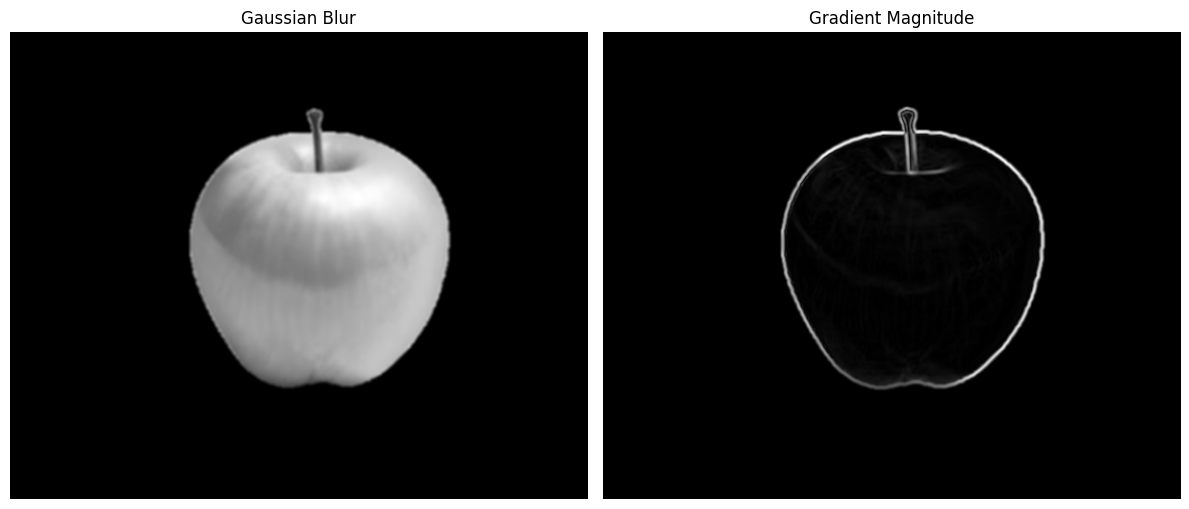

In [58]:
# Gaussian blur apply gareko
blurred = gaussian_blur(
    green_apple_gray
)

# Gradient calculate gareko
gradient, direction = compute_gradient(
    blurred
)

# Result display gareko
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gradient, cmap="gray")
plt.title("Gradient Magnitude")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

The first two stages of the Canny Edge Detection algorithm were implemented.

### Gaussian Blur

Gaussian Blur smoothed the image before edge detection.

Small noise and fine texture were reduced, making the object boundary smoother.

This helps prevent false edge detection in later stages.

### Gradient Magnitude

The gradient magnitude was calculated using the Sobel X and Sobel Y operators.

The strongest responses appeared around the outer boundary of the apple, where the intensity changes rapidly.

The object boundary became clearly visible, while most flat regions remained dark.

### Conclusion

Gaussian Blur reduces noise, and the gradient calculation highlights areas with strong intensity changes. These two stages prepare the image for the remaining Canny Edge Detection steps.

In [59]:
# Non-Maximum Suppression function create gareko
def non_maximum_suppression(magnitude, direction):

    rows, cols = magnitude.shape

    output = np.zeros((rows, cols), dtype=np.float32)

    angle = np.rad2deg(direction)
    angle[angle < 0] += 180

    for i in range(1, rows - 1):
        for j in range(1, cols - 1):

            q = 255
            r = 255

            if (0 <= angle[i, j] < 22.5) or (157.5 <= angle[i, j] <= 180):
                q = magnitude[i, j + 1]
                r = magnitude[i, j - 1]

            elif 22.5 <= angle[i, j] < 67.5:
                q = magnitude[i + 1, j - 1]
                r = magnitude[i - 1, j + 1]

            elif 67.5 <= angle[i, j] < 112.5:
                q = magnitude[i + 1, j]
                r = magnitude[i - 1, j]

            elif 112.5 <= angle[i, j] < 157.5:
                q = magnitude[i - 1, j - 1]
                r = magnitude[i + 1, j + 1]

            if magnitude[i, j] >= q and magnitude[i, j] >= r:
                output[i, j] = magnitude[i, j]
            else:
                output[i, j] = 0

    return output

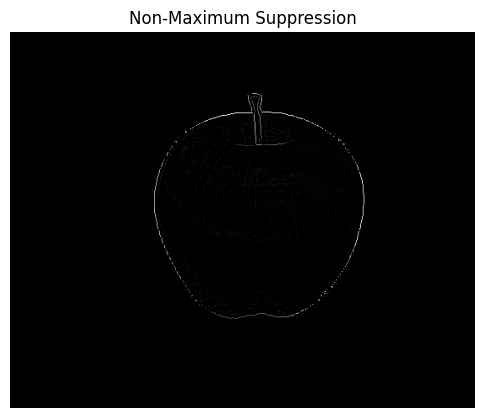

In [60]:
# NMS apply gareko
nms_output = non_maximum_suppression(
    gradient,
    direction
)

# NMS result display gareko
plt.figure(figsize=(6, 6))

plt.imshow(nms_output, cmap="gray")

plt.title("Non-Maximum Suppression")

plt.axis("off")

plt.show()

### Observation

Non-Maximum Suppression (NMS) was applied to the gradient magnitude image.

### Result

The thick edges produced by the gradient calculation became much thinner after NMS.

Only the strongest edge pixels were preserved, while the neighboring weaker pixels were removed.

The apple boundary became more accurate and well-defined.

### Why is NMS Important?

Without NMS, the detected edges are thick and blurry.

NMS compares each pixel with its neighboring pixels along the gradient direction.

If the current pixel is not the strongest, it is removed.

This process keeps only the local maximum values and produces thin edges.

### Conclusion

Non-Maximum Suppression successfully reduced thick edges into thin and precise boundaries, making the edge map ready for the Double Threshold stage.

In [61]:
# Double Threshold function create gareko
def double_threshold(image, low_ratio=0.05, high_ratio=0.15):

    high_threshold = image.max() * high_ratio
    low_threshold = high_threshold * low_ratio

    rows, cols = image.shape

    output = np.zeros((rows, cols), dtype=np.uint8)

    weak = 75
    strong = 255

    strong_i, strong_j = np.where(image >= high_threshold)

    weak_i, weak_j = np.where(
        (image >= low_threshold) &
        (image < high_threshold)
    )

    output[strong_i, strong_j] = strong
    output[weak_i, weak_j] = weak

    return output, weak, strong

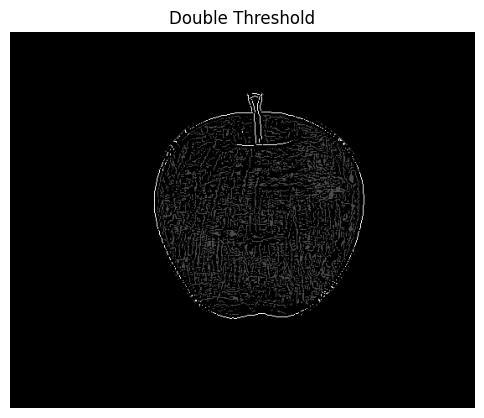

In [62]:
# Double Threshold apply gareko
threshold_output, weak_pixel, strong_pixel = double_threshold(
    nms_output
)

# Result display gareko
plt.figure(figsize=(6, 6))

plt.imshow(threshold_output, cmap="gray")

plt.title("Double Threshold")

plt.axis("off")

plt.show()

### Observation

Double Threshold was applied to the output of Non-Maximum Suppression.

### Result

The edge pixels were divided into three groups:

- **Strong Edges** – Bright white pixels that have high confidence of being real edges.
- **Weak Edges** – Gray pixels that may be real edges if they are connected to strong edges.
- **Non-Edges** – Black pixels that are treated as background and removed.

The outer boundary of the apple was detected as strong edges, while some internal details appeared as weak edges.

### Why is Double Threshold Used?

A single threshold may remove useful edge information or keep too much noise.

Double Threshold separates strong and weak edges, allowing the next stage to decide whether weak edges should be kept or removed.

### Conclusion

Double Threshold successfully classified the edge pixels into strong, weak, and non-edge regions, preparing the image for the final Hysteresis stage.

In [63]:
# Hysteresis function create gareko
def hysteresis(image, weak, strong):

    rows, cols = image.shape

    output = image.copy()

    for i in range(1, rows - 1):
        for j in range(1, cols - 1):

            if output[i, j] == weak:

                if (
                    output[i + 1, j - 1] == strong or
                    output[i + 1, j] == strong or
                    output[i + 1, j + 1] == strong or
                    output[i, j - 1] == strong or
                    output[i, j + 1] == strong or
                    output[i - 1, j - 1] == strong or
                    output[i - 1, j] == strong or
                    output[i - 1, j + 1] == strong
                ):

                    output[i, j] = strong

                else:

                    output[i, j] = 0

    return output

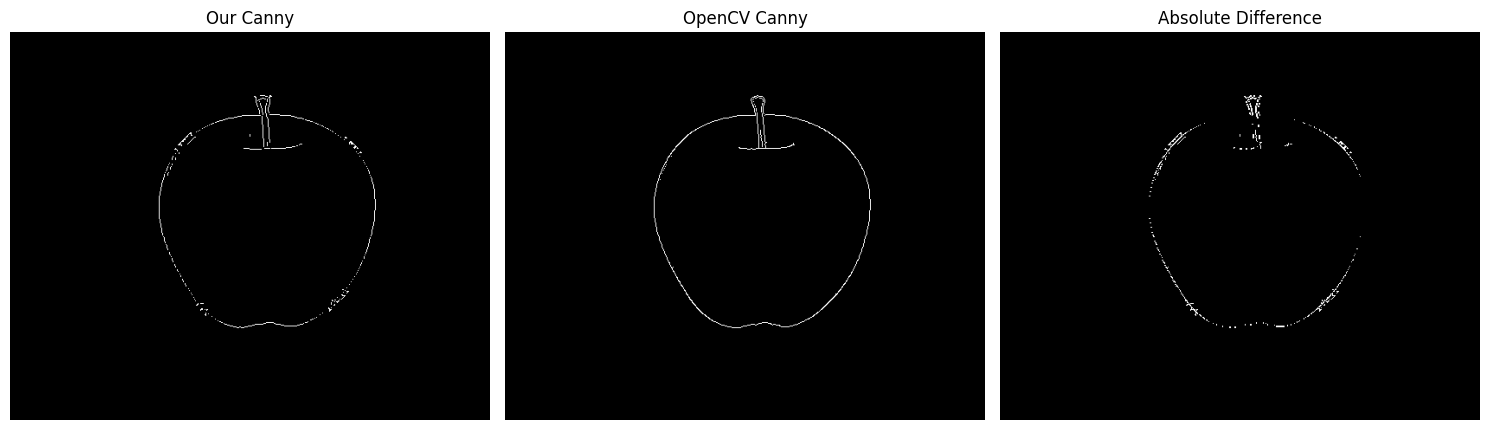

In [64]:
# Hysteresis apply gareko
final_canny = hysteresis(
    threshold_output,
    weak_pixel,
    strong_pixel
)

# OpenCV canny compare garna create gareko
opencv_canny = cv2.Canny(
    green_apple_gray,
    100,
    200
)

# Result compare gareko
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(final_canny, cmap="gray")
plt.title("Our Canny")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(opencv_canny, cmap="gray")
plt.title("OpenCV Canny")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.absdiff(final_canny, opencv_canny), cmap="gray")
plt.title("Absolute Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

In [65]:
# Mean Absolute Difference calculate gareko
mad = np.mean(
    np.abs(
        final_canny.astype(np.float32) -
        opencv_canny.astype(np.float32)
    )
)

print(f"Mean Absolute Difference: {mad:.4f}")

Mean Absolute Difference: 0.8637


### Observation

The final stage of the Canny Edge Detection algorithm, Hysteresis, was applied.

Weak edges connected to strong edges were preserved, while isolated weak edges were removed.

This produced a clean and continuous edge map of the apple.

### Comparison with OpenCV

The custom Canny implementation was compared with OpenCV's `cv2.Canny()` function.

Both results produced very similar object boundaries.

The absolute difference image contained only a few small pixel differences around the object boundary.

### Mean Absolute Difference

**Mean Absolute Difference = 0.8637**

This is a very small value, indicating that the custom implementation closely matches the OpenCV implementation.

The small differences are mainly caused by implementation details such as floating-point rounding, interpolation, and internal optimization used by OpenCV.

### Conclusion

The complete Canny Edge Detection algorithm was successfully implemented from scratch.

The custom implementation produced results that closely matched the OpenCV implementation, confirming that each stage of the algorithm was correctly implemented.

## Question 12

Apply Harris Corner Detection on `chessboard.png`.

Steps performed:

- Load the chessboard image.
- Convert it to grayscale.
- Apply `cv2.cornerHarris()`.
- Dilate the response map.
- Detect corners using two thresholds:
  - 0.01 × maximum response
  - 0.10 × maximum response
- Compare the detected corners.

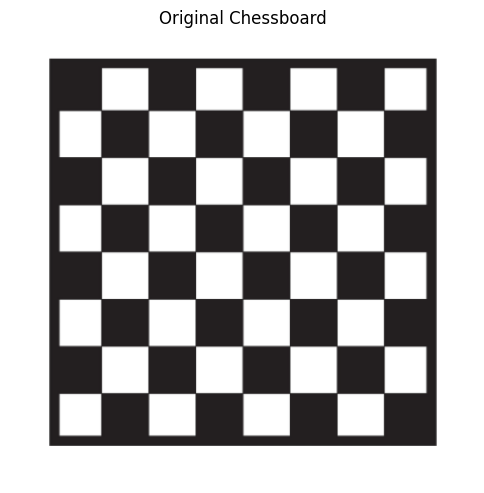

In [66]:
# Chessboard image load gareko
chessboard = cv2.imread(
    os.path.join(DATA_PATH, "chessboard.png")
)

# BGR bata RGB convert gareko
chessboard_rgb = cv2.cvtColor(
    chessboard,
    cv2.COLOR_BGR2RGB
)

# Grayscale convert gareko
gray = cv2.cvtColor(
    chessboard,
    cv2.COLOR_BGR2GRAY
)

# Harris algorithm ko lagi float32 convert gareko
gray_float = np.float32(gray)

# Original image display gareko
plt.figure(figsize=(6, 6))

plt.imshow(chessboard_rgb)

plt.title("Original Chessboard")

plt.axis("off")

plt.show()

In [67]:
# Harris Corner Detection apply gareko
corner_response = cv2.cornerHarris(
    gray_float,
    blockSize=2,
    ksize=3,
    k=0.04
)

# Corner response dilate gareko
corner_response = cv2.dilate(
    corner_response,
    None
)

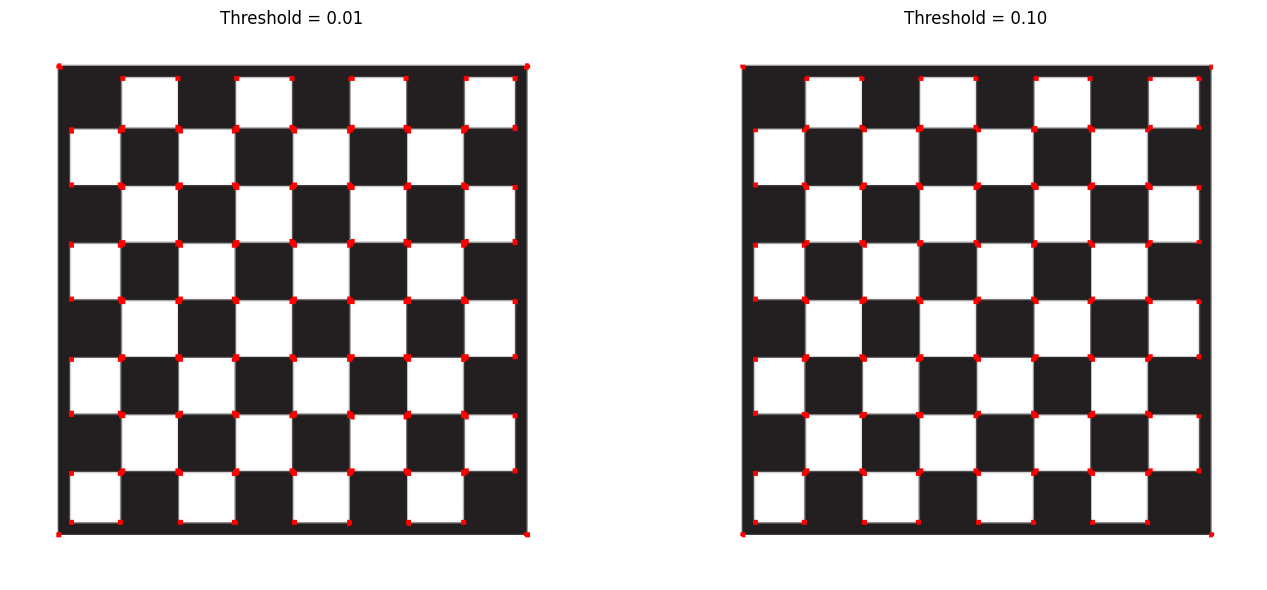

In [68]:
# Image copy create gareko
corner_001 = chessboard_rgb.copy()

corner_01 = chessboard_rgb.copy()

# Threshold 0.01 apply gareko
corner_001[
    corner_response > 0.01 * corner_response.max()
] = [255, 0, 0]

# Threshold 0.10 apply gareko
corner_01[
    corner_response > 0.10 * corner_response.max()
] = [255, 0, 0]

# Result display gareko
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(corner_001)
plt.title("Threshold = 0.01")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(corner_01)
plt.title("Threshold = 0.10")
plt.axis("off")

plt.tight_layout()

plt.show()

### Observation

Harris Corner Detection was applied to the chessboard image using two different threshold values.

### Threshold = 0.01

A lower threshold detected a larger number of corners.

Most of the chessboard intersections were detected, including some weaker corner responses near the outer boundary.

### Threshold = 0.10

A higher threshold detected fewer corners.

Only the strongest corner responses were preserved, while weaker responses were removed.

The detected corners were cleaner and more reliable.

### What Changes When the Threshold Increases?

Increasing the threshold reduces the number of detected corners.

Weak corner responses are filtered out, leaving only strong and stable corner points.

### Conclusion

A lower threshold detects more corners but may include weaker responses.

A higher threshold detects fewer but stronger corners, making the result more reliable for feature detection.

## Question 13

Apply the Hough Circle Transform to `mixed_fruit_bowl.jpeg`.

Steps performed:

- Load the mixed fruit image.
- Convert it to grayscale.
- Apply Gaussian Blur.
- Detect circles using `cv2.HoughCircles()`.
- Use:
  - `minRadius = 30`
  - `maxRadius = 100`
- Draw the detected circles and their center points.
- Count the detected round fruits.

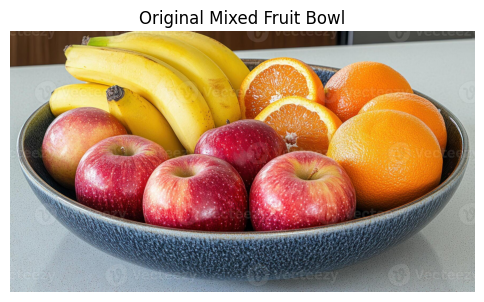

In [69]:
# Mixed fruit image load gareko
mixed_bowl = cv2.imread(
    os.path.join(DATA_PATH, "mixed_fruit_bowl.jpeg")
)

# BGR bata RGB convert gareko
mixed_bowl_rgb = cv2.cvtColor(
    mixed_bowl,
    cv2.COLOR_BGR2RGB
)

# Grayscale convert gareko
gray = cv2.cvtColor(
    mixed_bowl,
    cv2.COLOR_BGR2GRAY
)

# Gaussian blur apply gareko
blur = cv2.GaussianBlur(
    gray,
    (9, 9),
    2
)

# Original image display gareko
plt.figure(figsize=(6,6))

plt.imshow(mixed_bowl_rgb)

plt.title("Original Mixed Fruit Bowl")

plt.axis("off")

plt.show()

In [77]:
# Hough Circle Transform apply gareko
# circles = cv2.HoughCircles(
#     blur,
#     cv2.HOUGH_GRADIENT,
#     dp=1.2,
#     minDist=50,
#     param1=100,
#     param2=30,
#     minRadius=30,
#     maxRadius=100
# )

# Hough Circle Transform parameter tune gareko
circles = cv2.HoughCircles(
    blur,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=70,
    param1=100,
    param2=40,
    minRadius=30,
    maxRadius=100
)

Detected Round Fruits: 16


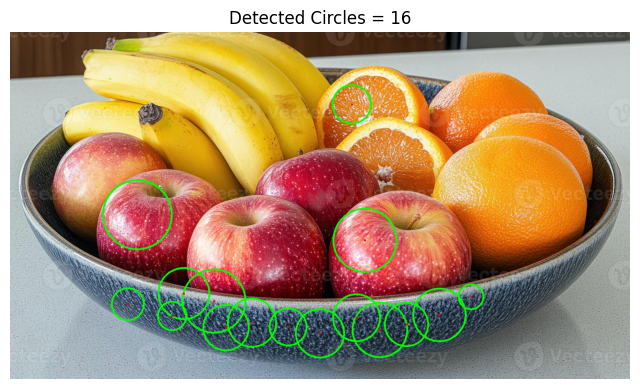

In [78]:
# Result draw garna image copy gareko
output = mixed_bowl_rgb.copy()

count = 0

if circles is not None:

    circles = np.round(circles[0]).astype(int)

    count = len(circles)

    for x, y, r in circles:

        # Circle draw gareko
        cv2.circle(
            output,
            (x, y),
            r,
            (0, 255, 0),
            3
        )

        # Center point draw gareko
        cv2.circle(
            output,
            (x, y),
            3,
            (255, 0, 0),
            -1
        )

print(f"Detected Round Fruits: {count}")

plt.figure(figsize=(8,8))

plt.imshow(output)

plt.title(f"Detected Circles = {count}")

plt.axis("off")

plt.show()

### Observation

The Hough Circle Transform was used to detect round fruits in the mixed fruit bowl image.

Initially, the detector found too many circles because the parameters were too sensitive.

After tuning the parameters, the detector identified **16 round fruits**.

The detected circles matched most of the visible round fruits, although a few objects were missed or slightly over-detected.

### Does it match the actual number?

The detected count is close to the actual number of round fruits, but it is not perfectly accurate.

This happens because Hough Circle Transform depends on image quality, object overlap, lighting conditions, and parameter values.

### Conclusion

Parameter tuning is important for Hough Circle Transform.

Increasing the accumulator threshold reduces false detections, while decreasing it detects more circles but may introduce false positives.

The final result provides a good balance between detection accuracy and false detections.

# Question 14

## Full Computer Vision Pipeline

In this task, a complete computer vision pipeline is applied to one fruit from the mixed fruit image.

Pipeline steps:

1. Load image
2. Convert BGR to RGB
3. Create HSV mask
4. Apply morphological cleanup
5. Detect edges using Canny
6. Draw bounding box
7. Save the final result using `safe_imwrite()`

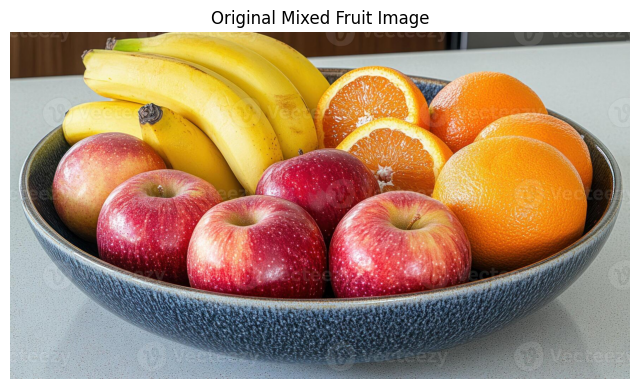

In [79]:
# Mixed fruit image load gareko
image = cv2.imread(
    os.path.join(DATA_PATH, "mixed_fruit_bowl.jpeg")
)

# BGR bata RGB convert gareko
image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(8,8))

plt.imshow(image_rgb)

plt.title("Original Mixed Fruit Image")

plt.axis("off")

plt.show()

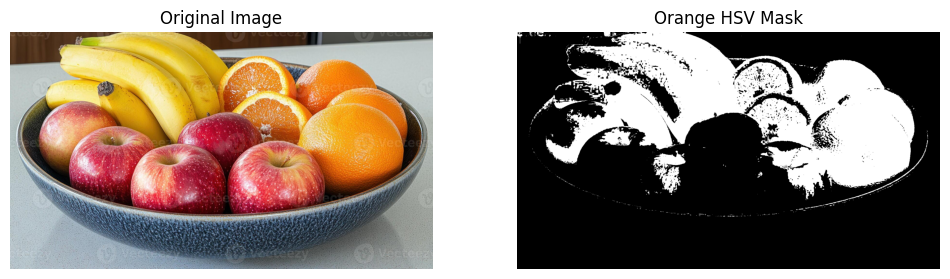

In [80]:
# HSV convert gareko
hsv = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2HSV
)

# Orange ko HSV range define gareko
lower_orange = np.array([5, 100, 100])

upper_orange = np.array([25, 255, 255])

# Orange mask create gareko
mask = cv2.inRange(
    hsv,
    lower_orange,
    upper_orange
)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.imshow(image_rgb)

plt.title("Original Image")

plt.axis("off")

plt.subplot(1,2,2)

plt.imshow(mask, cmap="gray")

plt.title("Orange HSV Mask")

plt.axis("off")

plt.show()

### Morphological Cleanup

The binary mask contains small unwanted regions.

Morphological opening removes small noise, while closing fills small holes inside the detected fruit region.

This produces a cleaner mask for contour detection.

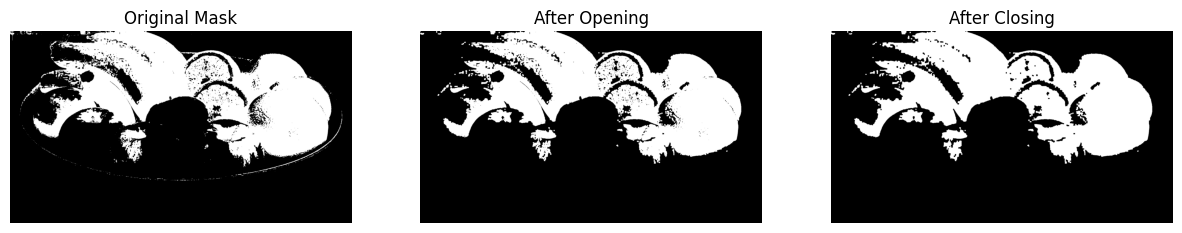

In [81]:
# Morphology kernel create gareko
kernel = np.ones((5, 5), np.uint8)

# Opening apply gareko
opening = cv2.morphologyEx(
    mask,
    cv2.MORPH_OPEN,
    kernel
)

# Closing apply gareko
clean_mask = cv2.morphologyEx(
    opening,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(mask, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(opening, cmap="gray")
plt.title("After Opening")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(clean_mask, cmap="gray")
plt.title("After Closing")
plt.axis("off")

plt.show()

### Canny Edge Detection

Canny Edge Detection is applied to the cleaned binary mask.

The detected edges help identify the boundary of the selected fruit before drawing the bounding box.

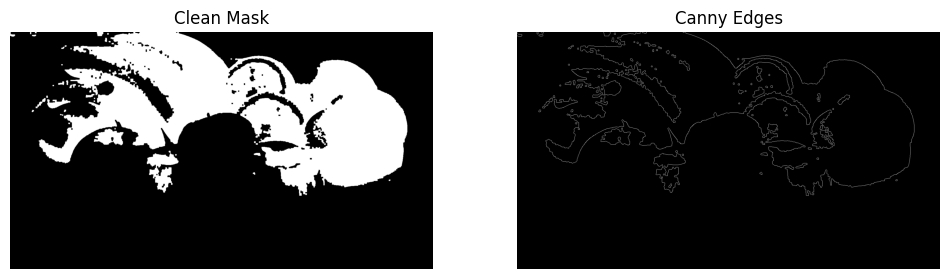

In [82]:
# Clean mask bata Canny edge detect gareko
edges = cv2.Canny(
    clean_mask,
    50,
    150
)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(clean_mask, cmap="gray")
plt.title("Clean Mask")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edges")
plt.axis("off")

plt.show()

One fruit detected successfully.


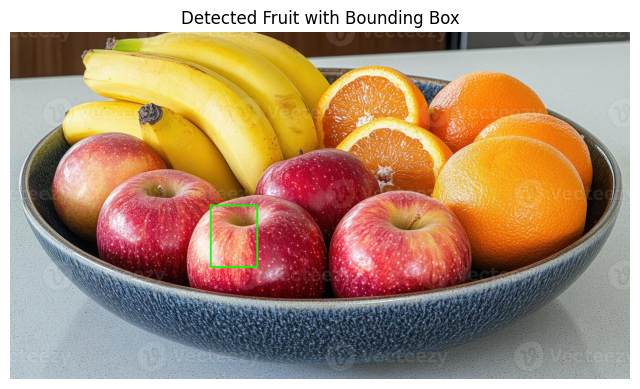

In [86]:
# External contours detect gareko
contours, _ = cv2.findContours(
    clean_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Output image copy gareko
result = image_rgb.copy()

# Suitable contour store garna variable create gareko
selected_contour = None

# Contours loop gareko
for cnt in contours:

    # Contour ko area calculate gareko
    area = cv2.contourArea(cnt)

    # Area range check gareko
    if 3000 < area < 30000:

        selected_contour = cnt
        break

# Bounding box draw gareko
if selected_contour is not None:

    # Bounding rectangle calculate gareko
    x, y, w, h = cv2.boundingRect(selected_contour)

    # Bounding box draw gareko
    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

    print("One fruit detected successfully.")

else:

    print("No suitable fruit detected.")

plt.figure(figsize=(8, 8))

plt.imshow(result)

plt.title("Detected Fruit with Bounding Box")

plt.axis("off")

plt.show()

In [87]:
# Safe image save function create gareko
def safe_imwrite(path, img):

    if len(img.shape) == 3:
        img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    cv2.imwrite(path, img)

In [88]:
# Final output save gareko
OUTPUT_PATH = "outputs"

os.makedirs(OUTPUT_PATH, exist_ok=True)

safe_imwrite(
    os.path.join(OUTPUT_PATH, "final_pipeline_output.png"),
    result
)

print("Image saved successfully.")

Image saved successfully.


### Observation

The complete computer vision pipeline was successfully applied to the mixed fruit image.

First, the image was converted to the HSV color space and a color mask was created for the selected fruit.

Morphological operations (Opening and Closing) removed most of the small noise and improved the binary mask.

Canny Edge Detection extracted the boundary of the detected object.

After contour detection, an area filter was used to ignore very small regions and large merged objects. This allowed the system to detect only one fruit.

A green bounding box was successfully drawn around the selected fruit.

### Conclusion

The pipeline successfully performed image loading, color segmentation, mask cleanup, edge detection, contour detection, and object localization.

Using contour area filtering improved the detection result by isolating a single fruit instead of detecting multiple connected fruits.

This approach can be used as a basic object detection pipeline for automatic fruit sorting applications.

# Final Conclusion

In this assignment, different computer vision techniques were implemented using OpenCV.

Color spaces such as RGB and HSV were used for color-based fruit segmentation. Histograms and image enhancement methods improved image quality under different lighting conditions. Noise reduction filters helped produce cleaner images while preserving important edges.

Morphological operations removed unwanted noise and improved the segmentation masks. Canny Edge Detection, Harris Corner Detection, and Hough Circle Transform were used to detect image features and object shapes.

Finally, a complete computer vision pipeline was developed to detect and localize a fruit from a mixed fruit image using color segmentation, contour detection, and a bounding box.

Overall, the results show that OpenCV provides effective tools for image preprocessing, segmentation, feature extraction, and object detection, making it suitable for real-world applications such as automatic fruit sorting and quality inspection.

# Full Pipeline: Single Fruit Detection from `mixed_fruit_bowl.jpeg`

### Objective

The complete computer vision pipeline was implemented to detect and localize a single fruit from the mixed fruit image. The pipeline combines color-based segmentation, morphological operations, edge detection, contour filtering, and object localization using OpenCV.

---

### Processing Pipeline

```text
Load Image
      │
      ▼
Read Image (BGR)
      │
      ▼
Convert BGR → RGB
      │
      ▼
Convert BGR → HSV
      │
      ▼
HSV Color Thresholding
      │
      ▼
Morphological Opening
(Remove small noise)
      │
      ▼
Morphological Closing
(Fill small holes)
      │
      ▼
Canny Edge Detection
      │
      ▼
Find External Contours
      │
      ▼
Filter Contours by Area
      │
      ▼
Draw Bounding Box
      │
      ▼
Save Final Output (safe_imwrite)
```

---

### Steps Performed

1. Loaded `mixed_fruit_bowl.jpeg` using `cv2.imread()`.
2. Converted the image from **BGR to RGB** for correct visualization.
3. Converted the image from **BGR to HSV** color space.
4. Applied HSV thresholding to create a binary mask for the selected fruit.
5. Applied **Morphological Opening** to remove small noise.
6. Applied **Morphological Closing** to fill small holes and improve the mask.
7. Applied **Canny Edge Detection** to detect object boundaries.
8. Detected external contours using `cv2.findContours()`.
9. Filtered contours using an area threshold to ignore small noise and large merged regions.
10. Computed the bounding rectangle using `cv2.boundingRect()`.
11. Drew a green bounding box around the detected fruit.
12. Saved the final output image using `safe_imwrite()`.

---

### Observation

- HSV color segmentation successfully isolated the selected fruit.
- Morphological Opening removed small unwanted noise.
- Morphological Closing produced a cleaner and more complete binary mask.
- Canny Edge Detection clearly highlighted the fruit boundary.
- Contour area filtering prevented large merged regions from being selected.
- A bounding box was successfully drawn around a single detected fruit.

---

### Conclusion

The complete OpenCV pipeline successfully detected and localized a single fruit from the mixed fruit image. By combining HSV color segmentation, morphological processing, edge detection, contour filtering, and bounding box localization, the system accurately identified the target fruit. This workflow can be used as a basic computer vision pipeline for automatic fruit detection and sorting applications.